# Рекомендательная система поисковых кластеров

**Исторический результат:** при десяти рекомендациях на товар найдено 60 будущих продающих пар вместо 51. Recall@10 вырос с **19,06% до 22,85% (+3,79 п.п.)**. Это качество рекомендаций, **не рост продаж**.

**Сравнение:** база — E5 + совместные продажи; полная система добавляет адаптер и LightGCN. Общий пул кандидатов, веса выбраны на validation. Будущие заказы — только ответы для оценки; ненайденные цели остаются в знаменателе.

**Просмотр:** графики и таблицы сохранены. По умолчанию читаются реальные обезличенные результаты; учебные данные — **синтетические**, модели обучаются заново. Экспертная разметка не является условием запуска.

**Повторение:** установите `requirements.txt`, выполните Restart Kernel → Run All; E5 скачивается один раз (~500 МБ), используется CPU. `RECOMPUTE_RESEARCH` включает пересчёт с приватными файлами; `RUN_PROSPECTIVE_CHECK` — будущую оценку без переобучения.

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

SUMMARY_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'src/recommender.py').is_file()), None)
if SUMMARY_ROOT is None:
    raise RuntimeError('Откройте ноутбук из папки клонированного проекта.')
sys.path.insert(0, str(SUMMARY_ROOT / 'src'))
from ranking_snapshot import snapshot_metrics

pair_path = SUMMARY_ROOT / 'reports/notebook_ranking_pairs.csv'
snapshot_info = json.loads((SUMMARY_ROOT / 'reports/notebook_ranking_manifest.json').read_text())
summary_path = SUMMARY_ROOT / 'reports/experiment_summary.json'
assert hashlib.sha256(pair_path.read_bytes()).hexdigest() == snapshot_info['pairs_sha256']
assert hashlib.sha256(summary_path.read_bytes()).hexdigest() == snapshot_info['experiment_summary_sha256']
real_pairs = pd.read_csv(pair_path, dtype={'baseline_rank': 'Int64', 'system_rank': 'Int64'})
summary_report = json.loads(summary_path.read_text())
assert set(real_pairs['period']) == {'test', 'new_days'}
measured_periods = {}
for period in ['test', 'new_days']:
    measured_periods[period] = snapshot_metrics(real_pairs.loc[real_pairs.period.eq(period)])
    for method, reference in [('baseline', 'e5_co_sales'), ('system', 'all_four')]:
        expected_metrics = summary_report['ablation'][period][reference]
        for metric_name in ['recall@10', 'precision@10', 'ndcg@10', 'retrieval_recall',
                            'evaluated_skus', 'positive_pairs']:
            assert np.isclose(measured_periods[period][method][metric_name],
                              expected_metrics[metric_name], rtol=1e-10, atol=1e-12)

real_test = real_pairs.loc[real_pairs.period.eq('test')].copy()
real_metrics = measured_periods['test']
print(f"Проверено: {len(real_test)} будущих продающих пар, {real_test.product_id.nunique()} товар.")
print('Позиции прочитаны из CSV; метрики пересчитаны и совпали с исходным отчётом.')

Проверено: 260 будущих продающих пар, 121 товар.
Позиции прочитаны из CSV; метрики пересчитаны и совпали с исходным отчётом.


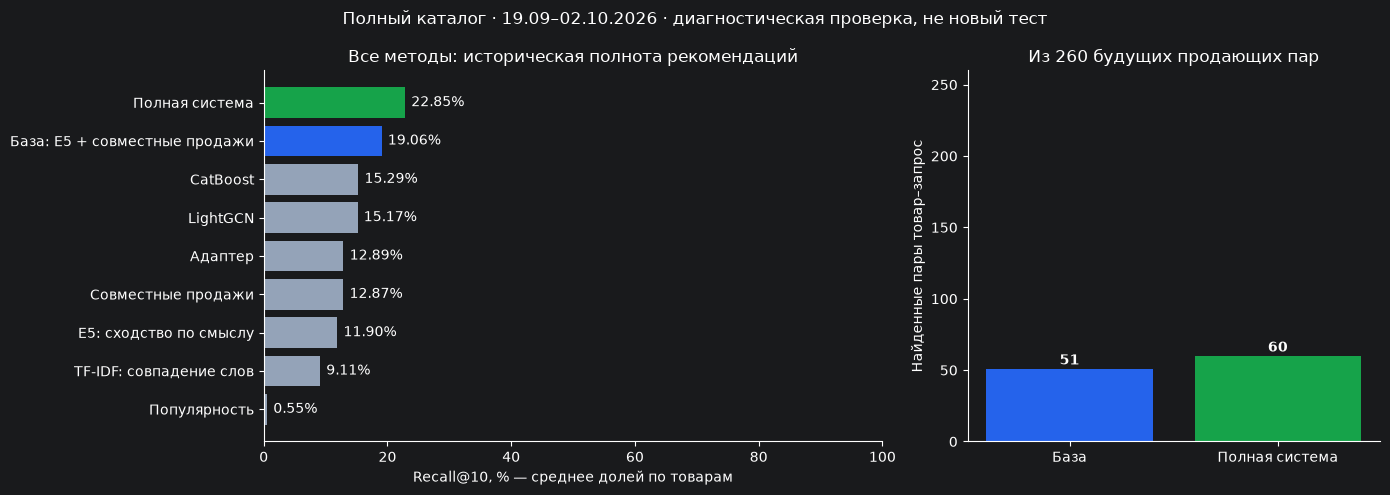

### Измеренное историческое улучшение
**19.06% → 22.85%: +3.79 п.п., +19.9% относительно сильной базы.** При тех же десяти местах найдено на **+9 продающих пар** больше. **Продажи не измерялись**: это не дополнительные заказы, не прирост выручки и не независимое подтверждение на новом периоде.

,"Recall@10, %",NDCG@10,Источник
Вариант,,,
Полная система,22.8486,0.1622,Пересчёт CSV
База: E5 + совместные продажи,19.0584,0.1327,Пересчёт CSV
CatBoost,15.2922,0.0964,Исходный отчёт
LightGCN,15.1666,0.1024,Исходный отчёт
Адаптер,12.8926,0.0932,Исходный отчёт
Совместные продажи,12.8680,0.0976,Исходный отчёт
E5: сходство по смыслу,11.8959,0.0767,Исходный отчёт
TF-IDF: совпадение слов,9.1116,0.0520,Исходный отчёт
Популярность,0.5510,0.0025,Исходный отчёт


Все методы: один пул, 121 товар и 260 положительных пар; ненайденные цели не исключены.
Столбцы 51 и 60 — общий счёт пар. Recall — среднее долей по товарам, не общий счёт / 260.
Показатели отдельных методов прочитаны из отчёта; база и полная система пересчитаны из CSV.


In [2]:
import matplotlib.pyplot as plt

def repeat_result_summary(report):
    controls = [row['Recall@10, %'] for row in report['ablation']
                if row['Вариант'] == 'База: E5 + co-sales']
    rows = report['seeds']
    if len(controls) != 1 or len(rows) < 2 or len({row['seed'] for row in rows}) != len(rows):
        raise ValueError('Нужны одна база и минимум два разных seed без отбора запусков.')
    baseline = float(controls[0])
    scores = np.asarray([row['Recall@10, %'] for row in rows], dtype=float)
    if not np.isfinite(baseline) or not 0 <= baseline <= 100 or not np.isfinite(scores).all() or ((scores < 0) | (scores > 100)).any():
        raise ValueError('Recall должен быть конечным процентом от 0 до 100.')
    return {'baseline': baseline, 'count': len(rows), 'mean': float(scores.mean()),
            'std': float(scores.std(ddof=1)), 'gain': float(scores.mean() - baseline),
            'minimum': float(scores.min()), 'maximum': float(scores.max()),
            'wins': int((scores > baseline).sum()), 'losses': int((scores < baseline).sum()),
            'ties': int((scores == baseline).sum())}

method_names = {'lexical': 'TF-IDF: совпадение слов', 'co_sales': 'Совместные продажи',
    'pretrained_embeddings': 'E5: сходство по смыслу', 'semantic_adapter': 'Адаптер',
    'lightgcn': 'LightGCN', 'popularity': 'Популярность', 'catboost_pu': 'CatBoost',
    'learned_fusion': 'Полная система', 'e5_co_sales': 'База: E5 + совместные продажи'}
comparison_rows = []
for method, metric in summary_report['test']['models'].items():
    reference = real_metrics['system'] if method == 'learned_fusion' else metric
    comparison_rows.append({'method': method, 'Вариант': method_names.get(method, method),
        'Recall@10, %': 100 * reference['recall@10'], 'NDCG@10': reference['ndcg@10'],
        'Источник': 'Пересчёт CSV' if method == 'learned_fusion' else 'Исходный отчёт'})
comparison_rows.append({'method': 'e5_co_sales', 'Вариант': method_names['e5_co_sales'],
    'Recall@10, %': 100 * real_metrics['baseline']['recall@10'],
    'NDCG@10': real_metrics['baseline']['ndcg@10'], 'Источник': 'Пересчёт CSV'})
full_comparison = pd.DataFrame(comparison_rows).set_index('method').sort_values('Recall@10, %', ascending=False)
assert set(full_comparison.index) == set(summary_report['test']['models']) | {'e5_co_sales'}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1.5, 1]})
colors = ['#16a34a' if method == 'learned_fusion' else '#2563eb' if method == 'e5_co_sales'
          else '#94a3b8' for method in full_comparison.index]
bars = axes[0].barh(full_comparison['Вариант'], full_comparison['Recall@10, %'], color=colors)
axes[0].invert_yaxis(); axes[0].set_xlim(0, 100)
axes[0].set_title('Все методы: историческая полнота рекомендаций')
axes[0].set_xlabel('Recall@10, % — среднее долей по товарам')
for bar, value in zip(bars, full_comparison['Recall@10, %']):
    axes[0].text(value + 1, bar.get_y() + bar.get_height() / 2, f'{value:.2f}%', va='center')
hits = [real_metrics[name]['hits'] for name in ['baseline', 'system']]
bars = axes[1].bar(['База', 'Полная система'], hits, color=['#2563eb', '#16a34a'])
axes[1].set_ylim(0, len(real_test)); axes[1].set_ylabel('Найденные пары товар–запрос')
axes[1].set_title(f'Из {len(real_test)} будущих продающих пар')
for bar, value in zip(bars, hits):
    axes[1].text(bar.get_x() + bar.get_width() / 2, value + 3, str(value), ha='center', fontweight='bold')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Полный каталог · 19.09–02.10.2026 · диагностическая проверка, не новый тест')
fig.tight_layout(); plt.show(); plt.close(fig)

recall_values = [100 * real_metrics[name]['recall@10'] for name in ['baseline', 'system']]
recall_gain = recall_values[1] - recall_values[0]
relative_gain = 100 * recall_gain / recall_values[0]
display(Markdown(f'### Измеренное историческое улучшение\n'
    f'**{recall_values[0]:.2f}% → {recall_values[1]:.2f}%: {recall_gain:+.2f} п.п., '
    f'{relative_gain:+.1f}% относительно сильной базы.** '
    f'При тех же десяти местах найдено на **{hits[1] - hits[0]:+d} продающих пар** больше. '
    '**Продажи не измерялись**: это не дополнительные заказы, не прирост выручки '
    'и не независимое подтверждение на новом периоде.'))
display(full_comparison.drop(columns=[])[['Вариант', 'Recall@10, %', 'NDCG@10', 'Источник']].set_index('Вариант').round(4))
print('Все методы: один пул, 121 товар и 260 положительных пар; ненайденные цели не исключены.')
print('Столбцы 51 и 60 — общий счёт пар. Recall — среднее долей по товарам, не общий счёт / 260.')
print('Показатели отдельных методов прочитаны из отчёта; база и полная система пересчитаны из CSV.')

### На каких запросах это видно?

**Пример выигрыша:** база поставила запрос ниже 10-го места, система подняла в первые 10, а позже по нему был заказ. Показываем и обратные случаи — система не выигрывает на каждом запросе.

`P…` — условный номер товара, `Q…` — условный номер реального поискового кластера. **Все строки исходного CSV — будущие продающие пары**, а не список всех рекомендаций. «Не найден» означает отсутствие в пуле кандидатов; такая цель всё равно участвует в оценке. Общий результат выше рассчитан по всем 260 парам, не только по примерам ниже.

In [3]:
baseline_hit = real_test['baseline_rank'].le(10).fillna(False)
system_hit = real_test['system_rank'].le(10).fillna(False)
gained = real_test.loc[system_hit & ~baseline_hit]
lost = real_test.loc[baseline_hit & ~system_hit]
shared = int((baseline_hit & system_hit).sum())
neither = int((~baseline_hit & ~system_hit).sum())
print(f'Полная система нашла, база пропустила: {len(gained)} пар.')
print(f'База нашла, полная система пропустила: {len(lost)} пар.')
print(f'Нашли оба варианта: {shared}. Не попали в первые 10 ни у одного: {neither}.')
assert len(gained) + len(lost) + shared + neither == len(real_test)

example_pairs = pd.concat([
    gained.head(3).assign(Итог='Выигрыш системы'),
    lost.head(3).assign(Итог='Потеря системы'),
])

def readable_rank(value):
    if pd.isna(value):
        return 'Не найден'
    return f'{int(value)} — в первых 10' if value <= 10 else f'{int(value)} — вне первых 10'

example_table = example_pairs[['product_id', 'query_id', 'Итог']].rename(
    columns={'product_id': 'Товар', 'query_id': 'Запрос'})
example_table['Место у базы'] = example_pairs['baseline_rank'].map(readable_rank)
example_table['Место у системы'] = example_pairs['system_rank'].map(readable_rank)
example_table['Заказ в следующие 14 дней'] = 'Да'
display(example_table.set_index(['Товар', 'Запрос']))

new_comparison = measured_periods['new_days']
new_interval = summary_report['ablation']['new_days_full_minus_control']
display(Markdown(
    f"**Дополнительная проверка, 04–07.10 (только 4 дня):** "
    f"{100 * new_comparison['baseline']['recall@10']:.2f}% → "
    f"{100 * new_comparison['system']['recall@10']:.2f}%. "
    f"95% интервал прироста: [{100 * new_interval['lower']:.2f}; "
    f"{100 * new_interval['upper']:.2f}] п.п. Включает ноль: "
    '**уверенного независимого подтверждения пока нет**.'))

Полная система нашла, база пропустила: 16 пар.
База нашла, полная система пропустила: 7 пар.
Нашли оба варианта: 44. Не попали в первые 10 ни у одного: 193.


,,Итог,Место у базы,Место у системы,Заказ в следующие 14 дней
Товар,Запрос,,,,
P0030,Q0019,Выигрыш системы,15 — вне первых 10,3 — в первых 10,Да
P0047,Q0017,Выигрыш системы,80 — вне первых 10,10 — в первых 10,Да
P0049,Q0152,Выигрыш системы,15 — вне первых 10,8 — в первых 10,Да
P0007,Q0321,Потеря системы,5 — в первых 10,12 — вне первых 10,Да
P0013,Q0323,Потеря системы,4 — в первых 10,29 — вне первых 10,Да
P0020,Q0307,Потеря системы,3 — в первых 10,13 — вне первых 10,Да


**Дополнительная проверка, 04–07.10 (только 4 дня):** 15.14% → 17.95%. 95% интервал прироста: [-2.08; 7.92] п.п. Включает ноль: **уверенного независимого подтверждения пока нет**.

## Проверки на реальных данных

Ниже — анализ данных, обучение, вклад моделей, повторы, шум и настройки. Используется **сокращённый каталог и своя база сравнения**; уже исследованные периоды не становятся независимым тестом.

По умолчанию читаются сохранённые обезличенные результаты. `RECOMPUTE_RESEARCH = True` пересчитывает их в ядре по приватным файлам из `config.json`, без подключения к базе.

In [4]:
from datetime import date
from time import perf_counter
import torch
from cluster_data import dictionary_snapshot, aggregate_clusters, period_pairs, future_positives, sha256
from cluster_recommender import load_embeddings, lexical_index, HybridRetriever
from full_history_recommender import DormantConfig, dormant_positives, enrich_candidates, graph_vectors
from dormant_learning import fit_fusion, fusion_scores, ranking_metrics, learning_rows, fit_ranker, predict_ranker

ROOT = SUMMARY_ROOT
torch.set_num_threads(2)
research_path = ROOT / 'reports/notebook_research.json'
research_config = json.loads((ROOT / 'config.json').read_text())
RECOMPUTE_RESEARCH = False
if RECOMPUTE_RESEARCH and not all((ROOT / research_config['inputs'][key]).is_file()
                                for key in ['facts', 'dictionary', 'embeddings']):
    raise RuntimeError('Для пересчёта нужны локальные факты, словарь и E5-векторы из config.json. Для просмотра оставьте RECOMPUTE_RESEARCH = False.')
research = {} if RECOMPUTE_RESEARCH else json.loads(research_path.read_text())
print('Режим:', 'пересчёт по реальным локальным файлам' if RECOMPUTE_RESEARCH else
      'чтение сохранённых реальных агрегатов; приватные файлы не требуются')
print('Для повторного обучения на реальной истории включите RECOMPUTE_RESEARCH; это отдельный, более долгий запуск.')
if RECOMPUTE_RESEARCH:
    facts = pd.read_csv(ROOT / research_config['inputs']['facts'],
                        dtype={'sku': 'string', 'query': 'string'}, keep_default_na=False)
    dictionary = pd.read_csv(ROOT / research_config['inputs']['dictionary'], keep_default_na=False)
    dictionary_time = pd.Timestamp('2026-06-26T23:59:59.999999999Z')
    real_snapshot, dictionary_audit = dictionary_snapshot(dictionary, dictionary_time)
    real_daily, mapping_audit = aggregate_clusters(facts, real_snapshot)
    real_catalog = sorted(real_snapshot.normquery.unique())
    real_vectors, embedding_metadata = load_embeddings(ROOT / research_config['inputs']['embeddings'], real_catalog)
    assert pd.Timestamp(embedding_metadata['dictionary_as_of']) == dictionary_time
    real_text = lexical_index(real_catalog)
    research['provenance'] = {key: sha256(ROOT / research_config['inputs'][key])
                              for key in ['facts', 'dictionary', 'embeddings']}
    print('Фактов:', len(facts), '| SKU:', facts.sku.nunique(), '| кластеров:', len(real_catalog))
    print('Нормализованных дневных строк:', len(real_daily), '| E5:', real_vectors.shape)

Режим: чтение сохранённых реальных агрегатов; приватные файлы не требуются
Для повторного обучения на реальной истории включите RECOMPUTE_RESEARCH; это отдельный, более долгий запуск.


### 1. Данные: распределения, пропуски, нормализация

| Поле | Значение после агрегации |
|---|---|
| `orders` | Сумма счётчиков заказов пары товар–кластер. |
| `views` | Сумма дневных `unique_view_users` по фразам кластера, не клики и не уникальные люди за период. |
| `searches` | Сумма дневных поисковых счётчиков; спрос кластера не дублируется по товарам. |
| `days` | Число наблюдавшихся дат пары, не длина окна. |

Отсутствующие даты — **пробелы, не нули**; неполные целевые окна не оцениваются. IQR отмечает выбросы без удаления: при IQR = 0 даже единица может формально стать выбросом. Покрытие словарём измеряет наличие соответствий, **не их смысловую правильность**.

Реальная выгрузка: 3203109 строк; 2171 SKU.
Дни без выгрузки: 2026-05-19, 2026-06-04, 2026-06-12, 2026-07-21
Дубли ключа: 0 | заказы без просмотров: 11285


,Поле,NULL,Пустая строка
0,date,0,0
1,sku,0,0
2,query,0,0
3,unique_search_users,0,0
4,unique_view_users,0,0
5,order_count,0,0


,field,zeros_pct,median,p95,p99,max,iqr_fence,above_fence
0,order_count,95.231,0.0,0.0,1.0,98.0,0.0,152751
1,unique_view_users,0.352,1.0,17.0,79.0,2930.0,6.0,383904
2,unique_search_users,0.687,5.0,1020.0,5584.0,42544.0,101.0,564054


,"Покрытие строк, %","Покрытие уникальных запросов, %","Покрытие заказов, %",Конфликтующих соответствий,Невалидных записей,Будущих записей исключено
0,58.93,9.15,82.24,13793,39553,0


,sample_size,decided,uncertain,unreviewed,accuracy_on_decided,wilson_95_on_decided,complete,sampling_unit
0,100,0,0,100,None,None,False,"uniform observed mapped query, not orders-weig..."


При незаполненной или частичной разметке точность всей нормализации не заявляется.


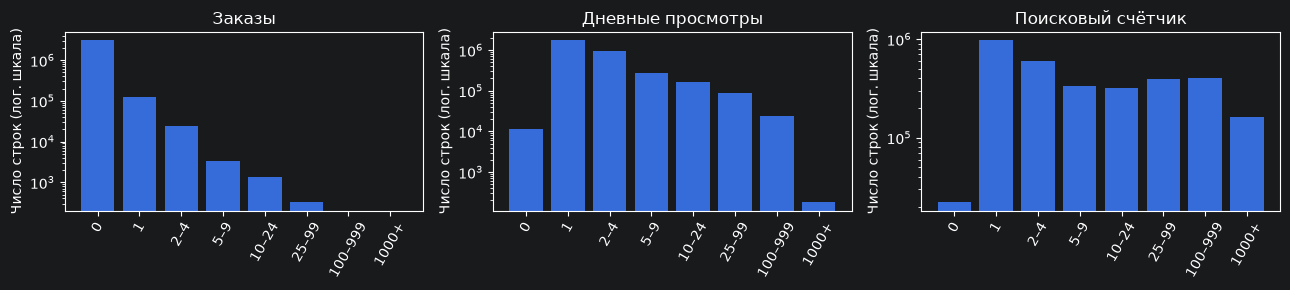

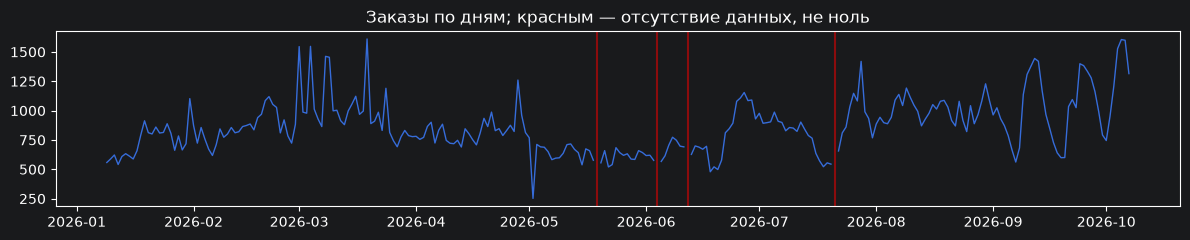

In [5]:
from notebook_research import data_overview, profile_scorer, tune_fusion, semantic_review_sample, semantic_review_summary
import matplotlib.pyplot as plt

if RECOMPUTE_RESEARCH:
    research['eda'] = data_overview(facts, real_snapshot)
    research['normalization'] = {**dictionary_audit,
        'selection': 'Последнее успешное соответствие; при равных датах — лексикографически последний кластер',
        'order_coverage_pct': 100 * mapping_audit['order_coverage'],
        'semantic_accuracy': None, 'review_status': 'awaiting_expert_labels'}
    audit_sample = semantic_review_sample(facts, real_snapshot, size=100, seed=7)
    private_audit = ROOT / 'data/notebook_normalization_observed_review.csv'
    if not private_audit.exists():
        audit_sample.to_csv(private_audit, index=False)
    reviewed_sample = pd.read_csv(private_audit, keep_default_na=False)
    research['semantic_review'] = semantic_review_summary(reviewed_sample, audit_sample)
    print('100 наблюдавшихся соответствий: data/notebook_normalization_observed_review.csv (приватный файл).')
    print('Разметка correct: 1 = верно, 0 = ошибка, ? = неоднозначно; пусто = не проверено.')

eda = research['eda']
print('Реальная выгрузка:', eda['rows'], 'строк;', eda['skus'], 'SKU.')
print('Дни без выгрузки:', ', '.join(eda['missing_days']))
print('Дубли ключа:', eda['duplicate_keys'], '| заказы без просмотров:', eda['orders_without_views_rows'])
display(pd.DataFrame(eda['fields']).rename(columns={'field': 'Поле', 'missing': 'NULL', 'blank': 'Пустая строка'}))
display(pd.DataFrame(eda['distributions']).round(3))
normalization = research['normalization']
display(pd.DataFrame([{
    'Покрытие строк, %': eda['row_mapping_pct'], 'Покрытие уникальных запросов, %': eda['query_mapping_pct'],
    'Покрытие заказов, %': normalization['order_coverage_pct'],
    'Конфликтующих соответствий': normalization['ambiguous_queries'],
    'Невалидных записей': normalization['invalid_historical_rows'],
    'Будущих записей исключено': normalization['future_rows_ignored'],
}]).round(2))
display(pd.DataFrame([research['semantic_review']]))
print('При незаполненной или частичной разметке точность всей нормализации не заявляется.')

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, column, title in zip(axes, ['order_count', 'unique_view_users', 'unique_search_users'],
                             ['Заказы', 'Дневные просмотры', 'Поисковый счётчик']):
    ax.bar(['0', '1', '2–4', '5–9', '10–24', '25–99', '100–999', '1000+'], eda['histograms'][column])
    ax.set_yscale('log'); ax.set_title(title); ax.tick_params(axis='x', rotation=60)
    ax.set_ylabel('Число строк (лог. шкала)')
fig.tight_layout(); plt.show(); plt.close(fig)
calendar = pd.DataFrame(eda['daily']).assign(date=lambda frame: pd.to_datetime(frame.date))
fig, ax = plt.subplots(figsize=(12, 2.5))
ax.plot(calendar.date, calendar.orders, linewidth=1)
for missing in eda['missing_days']:
    ax.axvline(pd.Timestamp(missing), color='red', alpha=.5)
ax.set_title('Заказы по дням; красным — отсутствие данных, не ноль')
fig.tight_layout(); plt.show(); plt.close(fig)

### 2. Время и размер повторного эксперимента

Для вычислительно доступного повторного исследования каталог фиксируется **только по наблюдениям до 21.08 и словарю от 26.06**. Он меньше полного каталога релиза.

- Обучение нейросетей: история по **21.08**.
- Выбор эпохи: решение 21.08, будущие ответы **22.08–04.09**.
- Выбор архитектуры и весов: решение 04.09, ответы **05–18.09**.
- Диагностическая проверка фиксированных настроек: решение 18.09, ответы **19.09–02.10**.

Эти окна не пересекаются. При выборе эпохи используется фиксированный пул четырёх необученных каналов — новые нейросети не подсказывают, какие цели добавить. Отдельно сравниваются одинаковый расширенный пул и собственный поиск каждого варианта.

In [6]:
if RECOMPUTE_RESEARCH:
    study_catalog = sorted(real_daily.loc[real_daily.date.le('2026-08-21'), 'normquery'].unique())
    catalog_positions = pd.Index(real_catalog).get_indexer(study_catalog)
    assert (catalog_positions >= 0).all()
    study_vectors = real_vectors[catalog_positions].copy()
    study_text = lexical_index(study_catalog)
    study_daily = real_daily.loc[real_daily.normquery.isin(study_catalog)].copy()
    study_config = DormantConfig(date(2026, 6, 26), date(2026, 6, 26),
        date(2026, 9, 4), date(2026, 9, 18), per_source=50, iterations=(40, 100, 300))
    source_days = pd.DatetimeIndex(pd.to_datetime(facts.date).unique())

    def study_split(decision, horizon=14, max_views=5, per_source=50, frame=None):
        cutoff = pd.Timestamp(decision)
        frame = study_daily if frame is None else frame
        history = period_pairs(frame, frame.date.min().date(), cutoff.date())
        recent = period_pairs(frame, (cutoff - pd.Timedelta(days=13)).date(), cutoff.date())
        full_recent = period_pairs(real_daily, (cutoff - pd.Timedelta(days=13)).date(), cutoff.date())
        required_days = pd.date_range(cutoff - pd.Timedelta(days=13), cutoff + pd.Timedelta(days=horizon))
        assert required_days.difference(source_days).empty, 'Неполное окно не оцениваем'
        active = set(full_recent.sku)
        part = frame.loc[frame.date.between(cutoff - pd.Timedelta(days=13), cutoff)]
        demand = part.drop_duplicates(['date', 'normquery']).groupby('normquery').cluster_searches.sum()
        base = HybridRetriever(study_catalog, history, demand, study_vectors, study_text).generate(
            per_source, max_history_views=max_views, traffic_history=recent, target_skus=active, max_seeds=32)
        full_history = period_pairs(real_daily, real_daily.date.min().date(), cutoff.date())
        future = period_pairs(real_daily, (cutoff + pd.Timedelta(days=1)).date(),
                              (cutoff + pd.Timedelta(days=horizon)).date())
        targets = dormant_positives(future_positives(full_history, future), full_recent, max_views, active)
        return {'base': base, 'history': history, 'recent': recent, 'demand': demand,
                'active': active, 'targets': targets, 'decision': decision}

    splits = {}
    for name, day in [('epoch_validation', '2026-08-21'), ('validation', '2026-09-04'), ('test', '2026-09-18')]:
        started = perf_counter()
        splits[name] = study_split(day)
        print(name, ': поиск выполнен за', round(perf_counter() - started, 1), 'с')
    neural_history = splits['epoch_validation']['history']
    research['study'] = {'catalog_clusters': len(study_catalog), 'full_catalog_clusters': len(real_catalog),
        'train_skus': int(neural_history.sku.nunique()), 'train_end': '2026-08-21',
        'per_source': 50, 'seeds': [7, 17, 27, 37, 47], 'status': 'reused_diagnostic_period',
        'splits': [{'name': name, 'decision': part['decision'], 'candidates': len(part['base']),
                    'target_skus': int(part['targets'].sku.nunique()), 'targets': len(part['targets']),
                    'targets_outside_catalog': int((~part['targets'].normquery.isin(study_catalog)).sum())}
                   for name, part in splits.items()]}
print('Каталог исследования:', research['study']['catalog_clusters'],
      'из', research['study']['full_catalog_clusters'], 'кластеров полного релиза.')
display(pd.DataFrame(research['study']['splits']))

Каталог исследования: 18444 из 477579 кластеров полного релиза.


,name,decision,candidates,target_skus,targets,targets_outside_catalog
0,epoch_validation,2026-08-21,47668,113,231,23
1,validation,2026-09-04,46760,104,228,18
2,test,2026-09-18,42900,121,260,48


### 3. Выбор лучшей эпохи

Максимум — 40 эпох; `patience = 5`, `min_delta = 0,0001`. Остановка — после пяти проверок без достаточного улучшения NDCG@10. Сохраняется любой строгий максимум, включая эпоху 0; лучшие веса восстанавливаются. Диагностический период не выбирает эпоху.

После короткой проверки запуска сравниваются размеры адаптера 128/64 и LightGCN 32/2, 16/2, 32/1. Меняется один параметр; архитектура выбирается на следующем validation-окне. Входные 384 измерения заданы E5.

,model,hidden_dim,best_epoch,epochs_completed,optimizer_steps,validation_ndcg@10,validation_recall@10,seconds,dimensions,layers
0,adapter,128.0,1,6,954,0.0714,0.1163,6.0172,NaN,NaN
1,adapter,64.0,1,6,954,0.0747,0.1307,5.5285,NaN,NaN
2,graph,NaN,11,15,15,0.1161,0.2013,2.1203,32.0,2.0
3,graph,NaN,3,8,8,0.1135,0.1682,1.2051,16.0,2.0
4,graph,NaN,7,12,12,0.0928,0.1508,1.7535,32.0,1.0


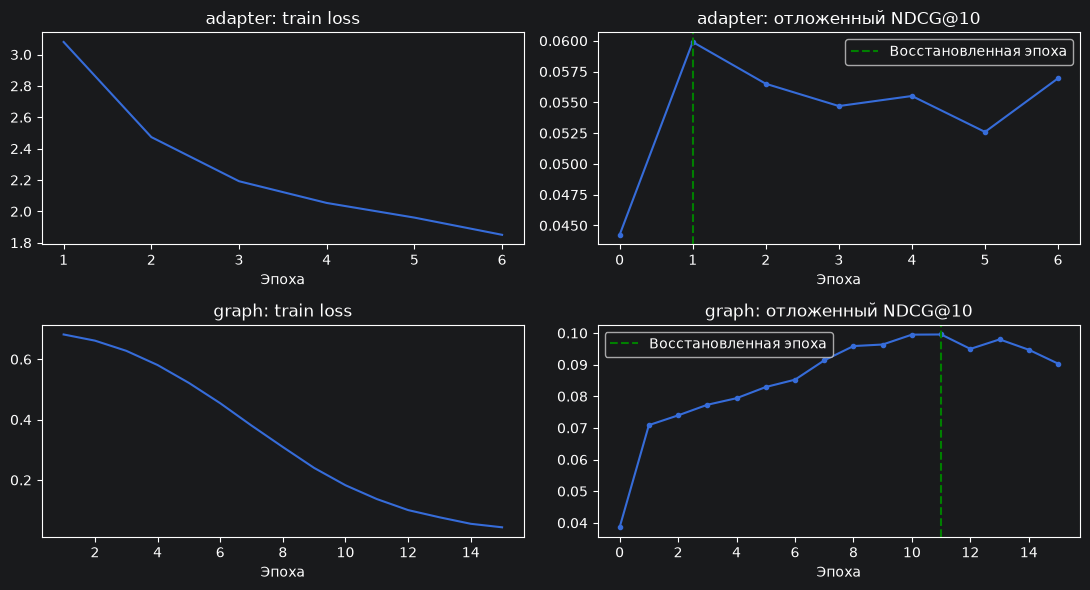

Выбрано на validation: {'adapter': {'hidden_dim': 64}, 'graph': {'dimensions': 32, 'layers': 2}}


In [7]:
from importlib import reload
import semantic_adapter, graph_learning
reload(semantic_adapter); reload(graph_learning)

if RECOMPUTE_RESEARCH:
    stop_split = splits['epoch_validation']
    adapter_scorer = profile_scorer(stop_split['base'], stop_split['history'], study_catalog, weighted=True)
    graph_scorer = profile_scorer(stop_split['base'], stop_split['history'], study_catalog, weighted=False)
    assert not stop_split['targets'].empty

    def stop_metric(scores):
        prediction = stop_split['base'][['sku', 'normquery']].assign(score=scores)
        return ranking_metrics(prediction, stop_split['targets'])['ndcg@10']

    def train_network(kind, seed=7, epochs=40, hidden_dim=128, dimensions=32, layers=2, history=None):
        history = neural_history if history is None else history
        started = perf_counter()
        options = dict(epochs=epochs, seed=seed, train_end='2026-08-21',
                       patience=5, min_delta=.0001, selection_metric='future NDCG@10: 22.08–04.09')
        if kind == 'adapter':
            model, audit = fit_adapter(history, study_catalog, study_vectors, batch_size=128,
                hidden_dim=hidden_dim, device='cpu',
                validation_callback=lambda current: stop_metric(adapter_scorer(apply_adapter(current, study_vectors))),
                **options)
            encoded = apply_adapter(model, study_vectors)
        else:
            model, audit = fit_graph(history, study_catalog, dimensions=dimensions, layers=layers,
                validation_callback=lambda current: stop_metric(graph_scorer(current.query_vectors(study_catalog)[0])),
                **options)
            encoded = model.query_vectors(study_catalog)[0]
        assert np.isfinite(encoded).all() and len(audit['validation_per_epoch']) == audit['epochs_completed'] + 1
        audit['seconds'] = perf_counter() - started
        return encoded, audit, model

    for kind in ['adapter', 'graph']:
        smoke_vectors, smoke_audit, _ = train_network(kind, epochs=1)
        assert smoke_audit['optimizer_steps'] > 0 and smoke_audit['best_validation_score'] is not None
        print('Короткая проверка', kind, ': отложенная метрика вычислена, scores конечны.')
    architectures = [('adapter', {'hidden_dim': 128}), ('adapter', {'hidden_dim': 64}),
                     ('graph', {'dimensions': 32, 'layers': 2}),
                     ('graph', {'dimensions': 16, 'layers': 2}), ('graph', {'dimensions': 32, 'layers': 1})]
    architecture_results = []
    trained_architectures = []
    validation_base = splits['validation']['base']
    for kind, parameters in architectures:
        encoded, audit, model = train_network(kind, **parameters)
        score = profile_scorer(validation_base, splits['validation']['history'], study_catalog,
                               weighted=kind == 'adapter')(encoded)
        metric = ranking_metrics(validation_base[['sku', 'normquery']].assign(score=score), splits['validation']['targets'])
        record = {'model': kind, **parameters, 'best_epoch': audit['best_epoch'],
                  'epochs_completed': audit['epochs_completed'], 'optimizer_steps': audit['optimizer_steps'],
                  'validation_ndcg@10': metric['ndcg@10'], 'validation_recall@10': metric['recall@10'],
                  'seconds': audit['seconds']}
        architecture_results.append(record)
        trained_architectures.append((encoded, audit, model))
        print(kind, parameters, ': лучшая эпоха', audit['best_epoch'], ', шагов', audit['optimizer_steps'])
    selected_architectures = {kind: max([i for i, value in enumerate(architectures) if value[0] == kind],
                              key=lambda i: architecture_results[i]['validation_ndcg@10']) for kind in ['adapter', 'graph']}
    selected_vectors = {kind: trained_architectures[index][0] for kind, index in selected_architectures.items()}
    research['architecture'] = architecture_results
    research['selected_parameters'] = {kind: architectures[index][1] for kind, index in selected_architectures.items()}
    research['curves'] = {kind: {key: trained_architectures[index][1][key] for key in
        ['validation_per_epoch', 'epochs_completed', 'best_epoch', 'optimizer_steps']} |
        {'loss': trained_architectures[index][1]['loss_per_epoch' if kind == 'adapter' else 'bpr_losses']}
        for kind, index in selected_architectures.items()}

display(pd.DataFrame(research['architecture']).round(4))
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for row, kind in enumerate(['adapter', 'graph']):
    curve = research['curves'][kind]
    axes[row, 0].plot(range(1, len(curve['loss']) + 1), curve['loss'])
    axes[row, 0].set_title(kind + ': train loss')
    axes[row, 1].plot(range(len(curve['validation_per_epoch'])), curve['validation_per_epoch'], marker='.')
    axes[row, 1].axvline(curve['best_epoch'], color='green', linestyle='--', label='Восстановленная эпоха')
    axes[row, 1].set_title(kind + ': отложенный NDCG@10'); axes[row, 1].legend()
    for ax in axes[row]: ax.set_xlabel('Эпоха')
fig.tight_layout(); plt.show(); plt.close(fig)
print('Выбрано на validation:', research['selected_parameters'])

### 4. Вклад каналов

Сравниваются база, добавление адаптера, LightGCN, обеих моделей и контроль с TF-IDF и популярностью, включая равные веса. В контрольных каналах нет дополнительного обучения; E5 остаётся предобученной нейросетью. Веса выбираются на validation, шаг сетки 0,25. CatBoost сравнивается отдельно.

**Общий пул** проверяет ранжирование; **собственный поиск** — систему целиком. Для него показана полнота поиска: доля будущих целей среди кандидатов. Одинаковый лимит на источник не означает одинаковый суммарный бюджет.

In [8]:
import dormant_learning
reload(dormant_learning)
from dormant_learning import fit_fusion, fusion_scores, ranking_metrics
from full_history_recommender import bootstrap_difference

variants = {
    'База: E5 + co-sales': ['pretrained_embeddings', 'co_sales'],
    'База + адаптер': ['pretrained_embeddings', 'co_sales', 'semantic_adapter'],
    'База + LightGCN': ['pretrained_embeddings', 'co_sales', 'lightgcn'],
    'Полные четыре': ['pretrained_embeddings', 'co_sales', 'semantic_adapter', 'lightgcn'],
    'Четыре без обучения': ['pretrained_embeddings', 'co_sales', 'lexical', 'popularity'],
}
source_by_channel = {'pretrained_embeddings': 'embedding', 'co_sales': 'graph',
    'semantic_adapter': 'adapter', 'lightgcn': 'lightgcn', 'lexical': 'text', 'popularity': 'popular'}

if RECOMPUTE_RESEARCH:
    def expanded_pool(part, encoded):
        return enrich_candidates(part['base'], part['history'], part['recent'], part['demand'],
            study_catalog, study_vectors, encoded['adapter'], encoded['graph'],
            study_text, study_config, part['active'])

    common_pools = {name: expanded_pool(part, selected_vectors) for name, part in splits.items()}
    chosen_fusions = {}
    ablation_rows = []
    retrieval_rows = []
    common_test = common_pools['test']
    common_targets = splits['test']['targets']
    for name, channel_names in variants.items():
        chosen = fit_fusion(common_pools['validation'], splits['validation']['targets'], channel_names)
        chosen_fusions[name] = chosen
        scores = fusion_scores(common_test, chosen['weights'])
        metric = ranking_metrics(common_test[['sku', 'normquery']].assign(score=scores), common_targets)
        ablation_rows.append({'Вариант': name, 'Recall@10, %': 100 * metric['recall@10'],
            'NDCG@10': metric['ndcg@10'], 'Validation NDCG@10': max(t['metrics']['ndcg@10'] for t in chosen['trials']),
            'Проверено весов': len(chosen['trials']), 'Веса': chosen['weights']})
        allowed_sources = {source_by_channel[channel] for channel in channel_names}
        own_pool = common_test.loc[common_test.retrieval_sources.map(
            lambda value: bool(set(value.split(',')) & allowed_sources))].copy()
        own_scores = fusion_scores(own_pool, chosen['weights'])
        own_metric = ranking_metrics(own_pool[['sku', 'normquery']].assign(score=own_scores), common_targets)
        retrieval_rows.append({'Вариант': name, 'Пул': len(own_pool),
            'Retrieval recall, %': 100 * own_metric['retrieval_recall'],
            'Recall@10, %': 100 * own_metric['recall@10'], 'NDCG@10': own_metric['ndcg@10']})
    equal_channels = variants['Четыре без обучения']
    equal_scores = fusion_scores(common_test, {channel: .25 for channel in equal_channels})
    equal_metric = ranking_metrics(common_test[['sku', 'normquery']].assign(score=equal_scores), common_targets)
    ablation_rows.append({'Вариант': 'Четыре без обучения: равные веса',
                          'Recall@10, %': 100 * equal_metric['recall@10'], 'NDCG@10': equal_metric['ndcg@10'],
                          'Проверено весов': 0, 'Веса': {channel: .25 for channel in equal_channels}})
    research['ablation'] = ablation_rows
    research['retrieval_ablation'] = retrieval_rows
    research['weights'] = {name: value['weights'] for name, value in chosen_fusions.items()}
    full_scores = fusion_scores(common_test, chosen_fusions['Полные четыре']['weights'])
    base_scores = fusion_scores(common_test, chosen_fusions['База: E5 + co-sales']['weights'])
    research['interval'] = bootstrap_difference(common_test, common_targets, full_scores, base_scores)

print('Один общий пул; все будущие цели, включая не найденные:')
display(pd.DataFrame(research['ablation']).drop(columns='Веса').round(4))
print('Собственный поиск каждого варианта:')
display(pd.DataFrame(research['retrieval_ablation']).round(3))
interval = research['interval']
print('Полный вариант минус база; paired SKU bootstrap 95%:',
      round(100 * interval['difference'], 2), 'п.п.; интервал',
      [round(100 * interval[key], 2) for key in ['lower', 'upper']])
print('Интервал описывает только этот уже исследованный период; это не независимое доказательство.')

Один общий пул; все будущие цели, включая не найденные:


,Вариант,"Recall@10, %",NDCG@10,Validation NDCG@10,Проверено весов
0,База: E5 + co-sales,17.5354,0.1165,0.1216,5
1,База + адаптер,19.0506,0.1247,0.1270,15
2,База + LightGCN,18.0077,0.1182,0.1454,15
3,Полные четыре,15.7113,0.0941,0.1529,35
4,Четыре без обучения,13.8085,0.0998,0.1249,35
5,Четыре без обучения: равные веса,11.6952,0.0805,NaN,0


Собственный поиск каждого варианта:


,Вариант,Пул,"Retrieval recall, %","Recall@10, %",NDCG@10
0,База: E5 + co-sales,24544,42.161,17.130,0.115
1,База + адаптер,26772,45.329,17.957,0.121
2,База + LightGCN,32904,50.877,18.008,0.118
3,Полные четыре,34966,51.566,15.700,0.095
4,Четыре без обучения,42900,47.560,13.602,0.099


Полный вариант минус база; paired SKU bootstrap 95%: -1.82 п.п.; интервал [-6.14, 2.33]
Интервал описывает только этот уже исследованный период; это не независимое доказательство.


In [9]:
print('Веса, выбранные до диагностического test:')
display(pd.DataFrame(research['weights']).T.fillna(0).round(2))
print('Названия вариантов задают разрешённые каналы; validation может присвоить некоторым нулевой вес.')
print('Нулевой вес не означает, что канал отдельно доказанно бесполезен: это результат данного окна и сетки.')

Веса, выбранные до диагностического test:


,pretrained_embeddings,co_sales,semantic_adapter,lightgcn,lexical,popularity
База: E5 + co-sales,0.50,0.50,0.00,0.0,0.0,0.00
База + адаптер,0.00,0.50,0.50,0.0,0.0,0.00
База + LightGCN,0.25,0.25,0.00,0.5,0.0,0.00
Полные четыре,0.25,0.00,0.25,0.5,0.0,0.00
Четыре без обучения,0.50,0.25,0.00,0.0,0.0,0.25


Названия вариантов задают разрешённые каналы; validation может присвоить некоторым нулевой вес.
Нулевой вес не означает, что канал отдельно доказанно бесполезен: это результат данного окна и сетки.


### 5. Повторное обучение и шум

Пять переобучений, seed 7/17/27/37/47: фиксированы архитектура, веса и будущие цели. Основная оценка — на общем пуле; собственный поиск показан отдельно.

Два стресс-сценария, по три переобучения: потеря 10% положительных обучающих связей и пуассоновский шум заказов. Меняется только обучающий сигнал нейросетей, не каталог, история для допуска кандидатов или будущие ответы. Эти проверки не заменяют новый период и смену сезона.

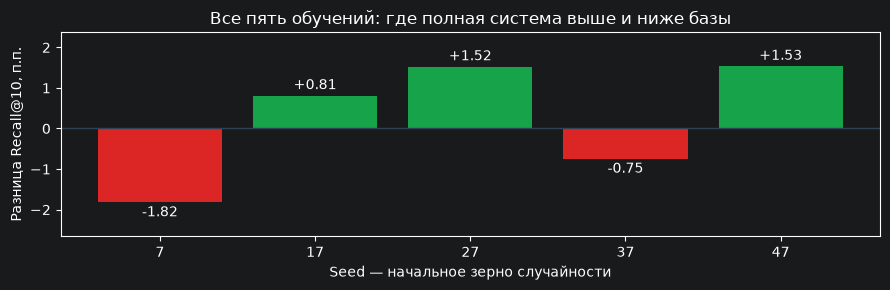

**Среднее всех 5 запусков: 17.79% против 17.54% у базы; разница +0.26 п.п.** Выше базы: 3; ниже: 2; равных: 0. Стандартное отклонение между запусками: 1.49 п.п.; диапазон 15.71–19.07%. Это среднее качества отдельных обучений, **не ансамбль пяти моделей** и не выбор лучшего seed. **Не независимый тест:** сокращённый каталог и уже исследованный период; небольшой средний прирост при проигрышах не доказывает устойчивое преимущество.

,seed,"Recall@10, %",NDCG@10,"Прирост к базе, п.п.","Собственный поиск Recall@10, %"
0,7,15.7113,0.0941,-1.8241,15.6995
1,17,18.3445,0.1147,0.8091,18.3937
2,27,19.0565,0.1166,1.5211,18.1828
3,37,16.7857,0.1087,-0.7497,17.0691
4,47,19.0676,0.1198,1.5322,21.3404


Разброс по пяти seed (std с ddof=1):


,"Recall@10, %",NDCG@10,"Прирост к базе, п.п.","Собственный поиск Recall@10, %"
mean,17.7931,0.1108,0.2577,18.1371
std,1.4894,0.0101,1.4894,2.0863
min,15.7113,0.0941,-1.8241,15.6995
max,19.0676,0.1198,1.5322,21.3404


Recall@10, %                           NDCG@10          \
                         mean     std      min      max    mean     std   
Сценарий                                                                  
Poisson заказов       16.3888  0.1461  16.3039  16.5575  0.1026  0.0042   
потеря 10% рёбер      16.7222  2.0087  14.6383  18.6462  0.1066  0.0107   

                                  
                     min     max  
Сценарий                          
Poisson заказов   0.0996  0.1073  
потеря 10% рёбер  0.0954  0.1167

Архитектуры и веса не менялись по результатам этих проверок.


In [10]:
if RECOMPUTE_RESEARCH:
    def score_on_pool(pool, part, encoded):
        result = pool.copy()
        result['adapter_score'] = profile_scorer(pool, part['history'], study_catalog, weighted=True)(encoded['adapter'])
        result['lightgcn_score'] = profile_scorer(pool, part['history'], study_catalog, weighted=False)(encoded['graph'])
        return result

    repeat_rows = []
    for seed in research['study']['seeds']:
        encoded = {}
        for kind in ['adapter', 'graph']:
            encoded[kind] = selected_vectors[kind] if seed == 7 else train_network(
                kind, seed=seed, **research['selected_parameters'][kind])[0]
        scored = score_on_pool(common_test, splits['test'], encoded)
        score = fusion_scores(scored, research['weights']['Полные четыре'])
        metric = ranking_metrics(scored[['sku', 'normquery']].assign(score=score), common_targets)
        own = expanded_pool(splits['test'], encoded)
        own = own.loc[own.retrieval_sources.map(lambda value: bool(
            set(value.split(',')) & {'embedding', 'graph', 'adapter', 'lightgcn'}))]
        own_metric = ranking_metrics(own[['sku', 'normquery']].assign(
            score=fusion_scores(own, research['weights']['Полные четыре'])), common_targets)
        repeat_rows.append({'seed': seed, 'Recall@10, %': 100 * metric['recall@10'],
            'NDCG@10': metric['ndcg@10'], 'Прирост к базе, п.п.': 100 * metric['recall@10'] - research['ablation'][0]['Recall@10, %'],
            'Собственный поиск Recall@10, %': 100 * own_metric['recall@10']})
        print('Повторное обучение seed', seed, 'завершено.')
    research['seeds'] = repeat_rows
    noise_rows = []
    for scenario in ['потеря 10% рёбер', 'Poisson заказов']:
        for seed in [7, 17, 27]:
            rng = np.random.default_rng(seed)
            damaged = neural_history.copy()
            if scenario == 'потеря 10% рёбер':
                damaged = damaged.loc[~(damaged.orders.gt(0) & (rng.random(len(damaged)) < .1))].copy()
            else:
                damaged['orders'] = rng.poisson(damaged.orders.to_numpy(dtype=float))
            encoded = {kind: train_network(kind, seed=seed, history=damaged,
                         **research['selected_parameters'][kind])[0] for kind in ['adapter', 'graph']}
            scored = score_on_pool(common_test, splits['test'], encoded)
            metric = ranking_metrics(scored[['sku', 'normquery']].assign(
                score=fusion_scores(scored, research['weights']['Полные четыре'])), common_targets)
            noise_rows.append({'Сценарий': scenario, 'seed': seed,
                'Recall@10, %': 100 * metric['recall@10'], 'NDCG@10': metric['ndcg@10']})
        print('Стресс-тест:', scenario, '— 3 переобучения завершены.')
    research['training_noise'] = noise_rows

repeats = pd.DataFrame(research['seeds'])
repeat_summary = repeat_result_summary(research)
assert repeats.seed.tolist() == research['study']['seeds'], 'Нельзя убрать неудачные запуски из итоговой таблицы'
repeat_gains = repeats['Recall@10, %'] - repeat_summary['baseline']
np.testing.assert_allclose(repeat_gains, repeats['Прирост к базе, п.п.'])
fig, ax = plt.subplots(figsize=(9, 3))
bars = ax.bar(repeats.seed.astype(str), repeat_gains,
              color=['#16a34a' if gain > 0 else '#dc2626' if gain < 0 else '#94a3b8' for gain in repeat_gains])
ax.axhline(0, color='#334155', linewidth=1)
ax.set_title('Все пять обучений: где полная система выше и ниже базы')
ax.set_xlabel('Seed — начальное зерно случайности'); ax.set_ylabel('Разница Recall@10, п.п.')
ax.margins(y=.25)
for bar, gain in zip(bars, repeat_gains):
    ax.text(bar.get_x() + bar.get_width() / 2, gain + (.08 if gain >= 0 else -.08),
            f'{gain:+.2f}', ha='center', va='bottom' if gain >= 0 else 'top')
fig.tight_layout(); plt.show(); plt.close(fig)
display(Markdown(f"**Среднее всех {repeat_summary['count']} запусков: {repeat_summary['mean']:.2f}% "
    f"против {repeat_summary['baseline']:.2f}% у базы; разница {repeat_summary['gain']:+.2f} п.п.** "
    f"Выше базы: {repeat_summary['wins']}; ниже: {repeat_summary['losses']}; равных: {repeat_summary['ties']}. "
    f"Стандартное отклонение между запусками: {repeat_summary['std']:.2f} п.п.; "
    f"диапазон {repeat_summary['minimum']:.2f}–{repeat_summary['maximum']:.2f}%. "
    'Это среднее качества отдельных обучений, **не ансамбль пяти моделей** и не выбор лучшего seed. '
    '**Не независимый тест:** сокращённый каталог и уже исследованный период; '
    'небольшой средний прирост при проигрышах не доказывает устойчивое преимущество.'))
display(repeats.round(4))
print('Разброс по пяти seed (std с ddof=1):')
display(repeats.drop(columns='seed').agg(['mean', 'std', 'min', 'max']).round(4))
noise = pd.DataFrame(research['training_noise'])
display(noise.groupby('Сценарий')[['Recall@10, %', 'NDCG@10']].agg(['mean', 'std', 'min', 'max']).round(4))
print('Архитектуры и веса не менялись по результатам этих проверок.')

### 6. Настройки и товарные срезы

На validation проверены лимиты кандидатов 25/50/100, пороги просмотров 0/5/10, деревья CatBoost 40/100/300 и шаг весов 0,25/0,1. Порог меняет состав пар; горизонты 7/14/28 — сами будущие цели, поэтому максимальная метрика не определяет лучший вариант задачи. Остальные константы широко не исследованы.

Срезы выполнены по объёму прошлой истории товара. Категорийных меток нет: срезы по типам товаров отсутствуют, категории не угадываются по SKU.

In [11]:
if RECOMPUTE_RESEARCH:
    sensitivity_rows = []
    for parameter, values in [('per_source', [25, 50, 100]), ('max_views', [0, 5, 10]), ('horizon', [7, 14, 28])]:
        for value in values:
            started = perf_counter()
            day = '2026-08-21' if parameter == 'horizon' else '2026-09-04'
            part = study_split(day, **{parameter: value})
            scores = fusion_scores(part['base'], research['weights']['База: E5 + co-sales'])
            metric = ranking_metrics(part['base'][['sku', 'normquery']].assign(score=scores), part['targets'])
            sensitivity_rows.append({'Параметр': parameter, 'Значение': value, 'Решение': day,
                'Целей': len(part['targets']), 'SKU': metric['evaluated_skus'], 'Пул': len(part['base']),
                'Recall@10, %': 100 * metric['recall@10'], 'Retrieval recall, %': 100 * metric['retrieval_recall'],
                'Секунд': perf_counter() - started})
    research['sensitivity'] = sensitivity_rows
    grid_rows = []
    for units in [4, 10]:
        started = perf_counter()
        choice = tune_fusion(common_pools['validation'], splits['validation']['targets'], variants['Полные четыре'], units=units)
        grid_rows.append({'Шаг': 1 / units, 'Вариантов': choice['trials'],
            'Validation NDCG@10': choice['ndcg@10'], 'Секунд': perf_counter() - started, 'Веса': choice['weights']})
    research['weight_grid'] = grid_rows

    ranker_split = study_split('2026-08-07')
    ranker_rows, _ = learning_rows(ranker_split['base'], ranker_split['targets'], seed=7)
    tree_rows = []
    fitted_rankers = []
    for trees in [40, 100, 300]:
        started = perf_counter()
        current_ranker = fit_ranker(ranker_rows, iterations=trees, seed=7)
        scores = predict_ranker(current_ranker, splits['validation']['base'])
        metric = ranking_metrics(splits['validation']['base'][['sku', 'normquery']].assign(score=scores),
                                 splits['validation']['targets'])
        tree_rows.append({'Деревьев': trees, 'Validation NDCG@10': metric['ndcg@10'],
                          'Validation Recall@10, %': 100 * metric['recall@10'], 'Секунд': perf_counter() - started})
        fitted_rankers.append(current_ranker)
    best_ranker_index = max(range(len(tree_rows)), key=lambda i: tree_rows[i]['Validation NDCG@10'])
    ranker_test_scores = predict_ranker(fitted_rankers[best_ranker_index], common_test)
    research['catboost_selection'] = tree_rows
    research['catboost_test'] = ranking_metrics(common_test[['sku', 'normquery']].assign(score=ranker_test_scores), common_targets)

    sold_counts = splits['test']['history'].loc[lambda frame: frame.orders.gt(0)].groupby('sku').size()
    sold_counts = sold_counts.reindex(common_targets.sku.unique(), fill_value=0)
    slice_rows = []
    for label, minimum, maximum in [('Нет продающих кластеров в каталоге', 0, 0),
            ('1–5 продающих кластеров', 1, 5), ('6–20 кластеров', 6, 20), ('21+ кластеров', 21, np.inf)]:
        group = set(sold_counts.loc[sold_counts.between(minimum, maximum)].index)
        targets = common_targets.loc[common_targets.sku.isin(group)]
        if targets.empty:
            continue
        row = {'История товара': label, 'SKU': int(targets.sku.nunique()), 'Целей': len(targets)}
        for name in ['База: E5 + co-sales', 'Полные четыре']:
            prediction = common_test[['sku', 'normquery']].assign(score=fusion_scores(common_test, research['weights'][name]))
            row[name + ', %'] = 100 * ranking_metrics(prediction.loc[prediction.sku.isin(group)], targets)['recall@10']
        slice_rows.append(row)
    assert sum(row['SKU'] for row in slice_rows) == common_targets.sku.nunique()
    assert sum(row['Целей'] for row in slice_rows) == len(common_targets)
    research['slices'] = slice_rows
    research['category_status'] = 'Нет датированной разметки товарных категорий; типы не выдумываются'

display(pd.DataFrame(research['sensitivity']).round(3))
display(pd.DataFrame(research['weight_grid']).drop(columns='Веса').round(4))
display(pd.DataFrame(research['catboost_selection']).round(4))
print('CatBoost: диагностический Recall@10 выбранного на validation числа деревьев =',
      round(100 * research['catboost_test']['recall@10'], 2), '%')
display(pd.DataFrame(research['slices']).round(3))
print('Срезы покрывают все SKU и все положительные цели, включая отсутствие истории в каталоге.')
print('Срез по категориям:', research['category_status'])
print('Новые таблицы не использованы для повторной настройки по test. Параметры рабочего релиза не заменены.')

,Параметр,Значение,Решение,Целей,SKU,Пул,"Recall@10, %","Retrieval recall, %",Секунд
0,per_source,25,2026-09-04,228,104,24459,21.426,37.696,4.824
1,per_source,50,2026-09-04,228,104,46760,22.628,53.737,5.617
2,per_source,100,2026-09-04,228,104,88147,21.587,65.894,6.450
3,max_views,0,2026-09-04,154,75,47093,13.203,41.756,5.210
4,max_views,5,2026-09-04,228,104,46760,22.628,53.737,5.287
5,max_views,10,2026-09-04,250,110,46683,24.707,55.505,5.205
6,horizon,7,2026-08-21,128,80,47668,13.333,51.022,5.347
7,horizon,14,2026-08-21,231,113,47668,17.583,53.338,5.217
8,horizon,28,2026-08-21,456,154,47668,20.326,55.044,5.284


,Шаг,Вариантов,Validation NDCG@10,Секунд
0,0.25,35,0.1529,4.4040
1,0.10,286,0.1560,36.9642


,Деревьев,Validation NDCG@10,"Validation Recall@10, %",Секунд
0,40,0.0779,14.5918,0.3825
1,100,0.0697,13.9187,0.3038
2,300,0.0592,10.6014,0.8366


CatBoost: диагностический Recall@10 выбранного на validation числа деревьев = 13.9 %


,История товара,SKU,Целей,"База: E5 + co-sales, %","Полные четыре, %"
0,Нет продающих кластеров в каталоге,12,25,0.000,0.000
1,1–5 продающих кластеров,16,31,22.708,12.396
2,6–20 кластеров,28,47,31.845,25.595
3,21+ кластеров,65,157,13.335,15.170


Срезы покрывают все SKU и все положительные цели, включая отсутствие истории в каталоге.
Срез по категориям: Нет датированной разметки товарных категорий; типы не выдумываются
Новые таблицы не использованы для повторной настройки по test. Параметры рабочего релиза не заменены.


### 7. Протокол независимой проверки

Зафиксированы модели seed 7, сокращённый каталог, база, веса и код. Решение — **16.10.2026**, цели — **17–30.10**, необходимая история — **03–16.10**. Оценка запускается только при полном окне, без переобучения и подбора настроек. Это проверка исследовательского варианта, не финального производственного дообучения.

In [12]:
import notebook_research
reload(notebook_research)
from notebook_research import prospective_status, evaluate_prospective

protocol_path = ROOT / 'reports/notebook_research_protocol.json'
frozen_path = ROOT / 'data/notebook_frozen_vectors.npz'
code_files = ['src/semantic_adapter.py', 'src/graph_learning.py', 'src/training_validation.py',
              'src/notebook_research.py', 'src/dormant_learning.py',
              'src/cluster_data.py', 'src/cluster_recommender.py', 'src/full_history_recommender.py']
if RECOMPUTE_RESEARCH:
    if not protocol_path.exists():
        np.savez_compressed(frozen_path, catalog=np.asarray(study_catalog), e5=study_vectors,
                            adapter=selected_vectors['adapter'], graph=selected_vectors['graph'])
        protocol = {'schema_version': 1, 'frozen_at': pd.Timestamp.now(tz='UTC').isoformat(),
            'decision': '2026-10-16', 'window_days': 14, 'train_end': '2026-08-21',
            'selection_end': '2026-09-18', 'dictionary_as_of': dictionary_time.isoformat(),
            'per_source': 50, 'max_views': 5, 'max_seeds': 32, 'seed': 7,
            'catalog_policy': 'dictionary 26.06 intersect queries observed by 21.08; no future extension',
            'selected_parameters': research['selected_parameters'], 'weights': research['weights'],
            'frozen_vectors_sha256': sha256(frozen_path),
            'code_sha256': {path: sha256(ROOT / path) for path in code_files},
            'source_sha256': research['provenance'],
            'primary_metric': 'macro recall@10', 'secondary_metric': 'macro ndcg@10',
            'criterion': 'full minus baseline > 0 and paired SKU bootstrap 95% lower > 0',
            'bootstrap_samples': 2000, 'bootstrap_seed': 7,
            'no_tuning_on_future': True, 'registration': 'local frozen artifact; not an external preregistration'}
        protocol_path.write_text(json.dumps(protocol, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
    else:
        protocol = json.loads(protocol_path.read_text())
        assert sha256(frozen_path) == protocol['frozen_vectors_sha256'], 'Фиксированные модели изменены'
        assert research['selected_parameters'] == protocol['selected_parameters']
        assert research['weights'] == protocol['weights'], 'Нельзя менять ранее зафиксированные веса'
    research['prospective'] = prospective_status(protocol, source_days,
        model_training_end=protocol['train_end'], selection_end=protocol['selection_end'])
    research['protocol_sha256'] = sha256(protocol_path)
    research['schema_version'] = 1
    research['limitations'] = ['Нет нового полного независимого периода', 'Нет экспертной разметки нормализации',
                              'Нет датированных товарных категорий', 'Повторное исследование использует сокращённый каталог']
    research_path.write_text(json.dumps(research, ensure_ascii=False, indent=2, allow_nan=False) + '\n', encoding='utf-8')
else:
    protocol = json.loads(protocol_path.read_text())
    assert sha256(protocol_path) == research['protocol_sha256']

repeat_summary = repeat_result_summary(research)
display(pd.DataFrame([
    {'Эксперимент': 'Полный каталог: сохранённое историческое ранжирование',
     'Кластеров': research['study']['full_catalog_clusters'],
     'База Recall@10, %': recall_values[0], 'Система Recall@10, %': recall_values[1],
     'Разница, п.п.': recall_gain, 'Что оценено': 'Один архивный вариант; не новый независимый тест'},
    {'Эксперимент': 'Сокращённый каталог: среднее всех пяти обучений',
     'Кластеров': research['study']['catalog_clusters'],
     'База Recall@10, %': repeat_summary['baseline'], 'Система Recall@10, %': repeat_summary['mean'],
     'Разница, п.п.': repeat_summary['gain'], 'Что оценено': 'Средний результат; есть выигрыши и проигрыши'},
]).set_index('Эксперимент').round(3))
display(Markdown('**Итог:** историческое улучшение измерено; повторное исследование показывает '
    'чувствительность полного варианта к обучению. Эти две проверки не следует смешивать. '
    'Независимое устойчивое превосходство и коммерческий эффект ещё не подтверждены.'))
print('Независимый период:', research['prospective']['target_start'], '—', research['prospective']['target_end'])
print('Статус:', research['prospective']['status'], '| недостающих целевых дней:',
      len(research['prospective']['missing_target_days']))
print('Протокол зафиксирован локально; для внешней фиксации сохраните его в истории Git до новых данных.')
print('Публично сохранены только агрегаты; модели и тексты остаются в data/, вне Git.')

,Кластеров,"База Recall@10, %","Система Recall@10, %","Разница, п.п.",Что оценено
Эксперимент,,,,,
Полный каталог: сохранённое историческое ранжирование,477579,19.058,22.849,3.790,Один архивный вариант; не новый независимый тест
Сокращённый каталог: среднее всех пяти обучений,18444,17.535,17.793,0.258,Средний результат; есть выигрыши и проигрыши


**Итог:** историческое улучшение измерено; повторное исследование показывает чувствительность полного варианта к обучению. Эти две проверки не следует смешивать. Независимое устойчивое превосходство и коммерческий эффект ещё не подтверждены.

Независимый период: 2026-10-17 — 2026-10-30
Статус: awaiting_unseen_data | недостающих целевых дней: 14
Протокол зафиксирован локально; для внешней фиксации сохраните его в истории Git до новых данных.
Публично сохранены только агрегаты; модели и тексты остаются в data/, вне Git.


In [13]:
RUN_PROSPECTIVE_CHECK = False
FUTURE_FACTS = ROOT / 'data/notebook_future_facts.csv'
if not RUN_PROSPECTIVE_CHECK:
    print('Полный пересчёт исследования включать не нужно: обучения и выбора параметров здесь нет.')
elif not FUTURE_FACTS.is_file():
    print('Независимая оценка не выполнена: файл новых фактов отсутствует.')
else:
    protocol_path = ROOT / 'reports/notebook_research_protocol.json'
    research_path = ROOT / 'reports/notebook_research.json'
    frozen_path = ROOT / 'data/notebook_frozen_vectors.npz'
    protocol = json.loads(protocol_path.read_text())
    research = json.loads(research_path.read_text())
    research_config = json.loads((ROOT / 'config.json').read_text())
    assert sha256(protocol_path) == research['protocol_sha256'], 'Зафиксированный протокол изменён'
    for path, digest in protocol['code_sha256'].items():
        assert sha256(ROOT / path) == digest, 'Код изменился после фиксации протокола'
    for key, digest in protocol['source_sha256'].items():
        assert sha256(ROOT / research_config['inputs'][key]) == digest, 'Исходный снимок изменён'
    assert sha256(frozen_path) == protocol['frozen_vectors_sha256'], 'Фиксированные модели изменены'
    facts = pd.read_csv(ROOT / research_config['inputs']['facts'],
                        dtype={'sku': 'string', 'query': 'string'}, keep_default_na=False)
    dictionary = pd.read_csv(ROOT / research_config['inputs']['dictionary'], keep_default_na=False)
    additional_facts = pd.read_csv(FUTURE_FACTS, dtype={'sku': 'string', 'query': 'string'}, keep_default_na=False)
    assert pd.to_datetime(additional_facts.date).min() > pd.to_datetime(facts.date).max(), 'Нельзя повторно включать старые строки'
    prospective_facts = pd.concat([facts, additional_facts], ignore_index=True)
    availability = prospective_status(protocol, pd.to_datetime(prospective_facts.date).unique(),
        model_training_end=protocol['train_end'], selection_end=protocol['selection_end'])
    if availability['status'] != 'ready':
        print('Независимая оценка не выполнена: окно неполное:', availability['status'])
        print('Недостающих дней истории:', len(availability['missing_history_days']))
        print('Недостающих целевых дней:', len(availability['missing_target_days']))
    else:
        with np.load(frozen_path, allow_pickle=False) as frozen:
            prospective_result = evaluate_prospective(prospective_facts, dictionary, frozen, protocol)
        assert not prospective_result['training_performed']
        assert not prospective_result['hyperparameter_selection_performed']
        display(pd.DataFrame(prospective_result['models']).T[['recall@10', 'ndcg@10', 'positive_pairs', 'evaluated_skus']])
        print('95% интервал:', prospective_result['interval'])
        print('Независимый эффект:', 'подтверждён' if prospective_result['effect_confirmed'] else 'не подтверждён')

Независимая оценка не выполнена: отдельная будущая проверка выключена.
После 30.10 добавьте локальную выгрузку 08–30.10 в data/notebook_future_facts.csv;
поставьте RUN_PROSPECTIVE_CHECK = True в этой ячейке и выполните её.
Полный пересчёт исследования включать не нужно: обучения и выбора параметров здесь нет.


In [14]:
import gc

# Полный каталог больше не нужен: сохраняем исследовательские модели, освобождаем крупные входы.
for large_input_name in ['facts', 'dictionary', 'real_daily', 'real_snapshot', 'real_vectors', 'real_text', 'real_catalog']:
    globals().pop(large_input_name, None)
gc.collect()
print('Крупные реальные входы освобождены из RAM; обученные исследовательские модели и агрегаты сохранены.')
print('Для повторного исследования начните с его загрузочной ячейки; будущая проверка загрузит входы сама.')

Крупные реальные входы освобождены из RAM; обученные исследовательские модели и агрегаты сохранены.
Для повторного исследования начните с его загрузочной ячейки; будущая проверка загрузит входы сама.


**Recall@10** — какую долю всех будущих продающих запросов удалось найти в первых десяти рекомендациях. Эти доли усредняются по товарам. Поэтому 51 и 60 попаданий — общий счёт пар, а 19,06% и 22,85% — средние доли, не результат деления на 260. Одна продающая пара не равна одному заказу.

Не смешиваем три оценки:
- **Полный каталог:** архивное историческое сравнение, 477 579 кластеров.
- **Сокращённый каталог:** повторные эксперименты, 18 444 кластера; у них своя база сравнения.
- **Независимый период:** протокол зафиксирован, результат ещё не получен.

95%-й интервал рассчитывается повторной выборкой товаров с сохранением пары результатов методов. Он отражает неопределённость, но не устраняет подгонку по знакомому периоду.

### Тестовый период уже использован

Сентябрьская оценка обозначена как **диагностика**, а не независимый тест. Исторический прирост +3,79 п.п. сохранён, но не доказывает перенос на новые данные. Дополнительные четыре дня дали 15,14% → 17,95%; интервал прироста [−2,08; +7,92] п.п. включает ноль.

Для независимой проверки зафиксированы модели, каталог, веса и код: решение 16.10, цели 17–30.10, без переобучения и донастройки. Критерий — нижняя граница 95%-го интервала разницы Recall@10 выше нуля. Данные пока заканчиваются 07.10: **тест ещё не выполнен**. Фиксация локальная, не внешняя предварительная регистрация.

### Анализ данных и нормализация

Добавлены распределения, пропуски, дубли и выбросы для 3,2 млн строк и 2 171 товара. Четыре отсутствующих дня — 19.05, 04.06, 12.06, 21.07 — оставлены пробелами, не нулями. Выбросы автоматически не удаляются; отдельно отмечены 11 285 строк с заказами без просмотров.

`views` — сумма дневных просмотров по фразам кластера, не уникальные люди за весь период. `days` — число наблюдавшихся дат пары, не длина окна.

Для внешнего словаря проверены конфликты и покрытие: **58,93% строк, 9,15% уникальных фраз, 82,24% заказов**. Это техническое покрытие. **Смысловая точность нормализации не измерена:** экспертных меток нет, версия алгоритма словаря неизвестна.

### Устойчивость

На **сокращённом каталоге** выполнены пять переобучений: средний Recall@10 **17,79% против 17,54% у базы**, прирост +0,26 п.п., стандартное отклонение **1,49 п.п.** Три запуска выше базы, два ниже. Это среднее отдельных моделей, не ансамбль пяти моделей; устойчивое преимущество не установлено.

Добавлены два стресс-сценария, по три переобучения: потеря 10% положительных обучающих связей и пуассоновский шум заказов. Меняется только обучающий сигнал нейросетей, не вся система.

Есть срезы по объёму прошлой истории, но это **не типы товаров**. Срезы по категориям без достоверных меток не выдумываются.

### Вклад моделей, а не число источников

Выполнены отключения компонентов и контроль «E5 + совместные продажи + TF-IDF + популярность». **Общий пул кандидатов** отделяет ранжирование от расширения поиска; собственный поиск вариантов показан отдельно. Веса выбраны на validation.

Сокращённый каталог, seed 7:

| Вариант | Recall@10 |
|---|---:|
| База | 17,54% |
| База + адаптер | 19,05% |
| База + LightGCN | 18,01% |
| База + обе модели | 15,71% |
| Контроль с TF-IDF и популярностью | 13,81% |

Отдельные добавления помогли в этом опыте, совместное — нет. **Ни большее число источников, ни обе нейросети вместе не гарантируют улучшения.** Это диагностическое сравнение, не независимый выбор победителя.

### Защита от возможных утечек

Словарь и TF-IDF строятся только по доступному на дату решения каталогу. В реальном исследовании это словарь от 26.06 и наблюдения по 21.08; в учебном примере будущая фраза явно исключается.

Регрессионная проверка добавляет будущий запрос и **999 будущих заказов и просмотров**: прежняя выдача, каталог и TF-IDF не меняются. Будущий снимок карточки отклоняется. Проверены конкретные пути утечки, а не все возможные ошибки. Архивные метрики этим задним числом не переоцениваются.

### Обоснование настроек

Архитектуры, число деревьев и веса сравнивались по **NDCG@10 на validation**, не на диагностическом периоде.

| Настройка | Основание |
|---|---|
| E5 / адаптер | 384 — выход E5; скрытый размер 64 выбран из 64/128. |
| LightGCN | 32 измерения / 2 слоя выбраны из 32/2, 16/2, 32/1. |
| CatBoost: 40 деревьев | Быстрое демо; на реальных данных 40 лучше проверенных 100/300. |
| `per_source` | 12 — скорость демо, 50 — исследование, 150 — релиз; проверены 25/50/100. |
| 5 просмотров | Рабочая граница малотрафиковых пар; проверены 0/5/10. |
| 14 дней | Два недельных цикла; 7/14/28 задают разные цели, не равнозначные варианты качества. |
| Шаг весов 0,25 | 35 сочетаний против 286 при 0,1; тонкая сетка чуть лучше на validation, протокол не менялся. |

### Контроль обучения

В новом исследовании показаны кривые обучающей ошибки и **NDCG@10 на отдельном окне**. Максимум — 40 эпох; остановка после пяти проверок без улучшения на 0,0001. Проверяется эпоха 0, сохраняется любой строгий максимум и восстанавливаются лучшие веса. Диагностический период не выбирает эпоху.

- **Адаптер:** 6 эпох, 954 шага; восстановлена эпоха 1.
- **LightGCN:** 15 эпох, 15 шагов — весь набор обрабатывается одним пакетом; восстановлена эпоха 11.

Падение обучающей ошибки само по себе не доказывает качество рекомендаций. Эта проверка относится к **новому исследованию**, не подтверждает обучение архивных весов задним числом.

---

## Учебный пример: как работают модели

Далее используются **синтетические данные** и настоящий код моделей: тексты → обучение → рекомендации → защитная фильтрация. Пример запускается без приватных данных и не доказывает качество на реальной истории. Система формирует очередь для человека, не меняет карточки автоматически.

In [15]:
from pathlib import Path
from datetime import date
from importlib.metadata import version
import hashlib
import json
import os
import sys
import tempfile
import warnings

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/recommender.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Откройте ноутбук из папки клонированного проекта.')
sys.path.insert(0, str(ROOT / 'src'))
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
warnings.filterwarnings('ignore', message='IProgress not found.*')

import numpy as np
import pandas as pd
import torch
from IPython.display import display
from cluster_recommender import HybridRetriever, lexical_index
from dormant_learning import learning_rows, fit_ranker, fit_fusion, ranking_metrics
from semantic_adapter import fit_adapter, apply_adapter
from graph_learning import fit_graph
from full_history_recommender import DormantConfig, enrich_candidates, graph_vectors, refinement_scores
from seo_recommendation_policy import annotate_recommendations, review_top_k

SEED = 7
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
pd.set_option('display.max_colwidth', 65)
RUN_PRIVATE_CHECK = (ROOT / 'reports/stage3_release/manifest.json').is_file()
# Можно поставить False: приватный релиз не нужен для учебных разделов 1–8.
print('Готово: seed = 7, CPU; база данных не используется.')
display(pd.DataFrame([(name, version(name)) for name in
    ['numpy', 'pandas', 'torch', 'sentence-transformers', 'catboost']],
    columns=['Библиотека', 'Версия']))

Готово: seed = 7, CPU; база данных не используется.


,Библиотека,Версия
0,numpy,2.5.3
1,pandas,3.0.6
2,torch,2.14.1
3,sentence-transformers,5.7.0
4,catboost,1.2.10


## 1. Учебные данные и словарь

Три вымышленных товара и товары-соседи. Словарь доступен с 01.08; будущая фраза от 05.09 исключается.

Обучение нейросетей — по 07.08; выбор эпохи и цели CatBoost — 08–21.08; настройка весов — 22.08–04.09; test — 05–18.09. На test веса фиксированы. Нулевые заказы не доказывают нерелевантность запроса.

In [16]:
groups = {
    '101': ['пакеты для мусора', 'мешки мусорные 60 л', 'пакеты мусорные прочные',
            'мешки для мусора с завязками', 'пакеты для мусора плотные',
            'пакеты для мусора черные', 'пакеты для мусора 120 л', 'пакеты для заморозки'],
    '102': ['салфетки из микрофибры', 'салфетки для уборки', 'тряпки для уборки микрофибра',
            'салфетки для стекол', 'салфетки для пыли', 'салфетки универсальные',
            'салфетки из целлюлозы', 'губки для посуды'],
    '103': ['перчатки нитриловые', 'перчатки одноразовые', 'перчатки нитриловые без пудры',
            'перчатки для уборки нитриловые', 'перчатки защитные нитриловые',
            'перчатки хозяйственные', 'перчатки латексные', 'перчатки виниловые'],
}
catalog = sorted({q for queries in groups.values() for q in queries})
products = pd.DataFrame([
    ['101', 'Пакеты для мусора 60 л', 'Прочные мешки для бытового мусора.', 'Учебный бренд'],
    ['102', 'Салфетки из микрофибры', 'Для домашней уборки поверхностей.', 'Учебный бренд'],
    ['103', 'Перчатки нитриловые', 'Одноразовые защитные перчатки.', 'Учебный бренд'],
], columns=['sku', 'name', 'description', 'brand']).assign(
    attributes_json='[]', attributes_status='ok', snapshot_at='2026-08-01T00:00:00Z')

records = []
for sku, queries in groups.items():
    peer = str(int(sku) + 100)
    for decision in ['2026-08-07', '2026-08-21', '2026-09-04']:
        for q in queries[:2]:
            records.append([decision, sku, q, 3, 15, 30, 1])
        for q in queries[:5]:
            records.append([decision, peer, q, 2, 10, 20, 1])
        records.append([decision, sku, queries[5], 0, 12, 30, 1])
    for day, q in zip(['2026-08-08', '2026-08-22', '2026-09-05'], queries[2:5]):
        records.append([day, sku, q, 1, 2, 10, 1])
events = pd.DataFrame(records, columns=['date', 'sku', 'normquery', 'orders', 'views', 'searches', 'days'])
events['date'] = pd.to_datetime(events['date'])
config = DormantConfig(date(2026, 8, 1), date(2026, 8, 7), date(2026, 8, 21),
    date(2026, 9, 4), window_days=14, per_source=12, iterations=(40,), seed=SEED)
train_events = events.loc[events['date'].le('2026-08-07')].copy()
assert not events.isna().any().any()
assert train_events['date'].max() < pd.Timestamp('2026-08-08')
print(f'Учебные данные: {len(events)} событий, {events.sku.nunique()} SKU, {len(catalog)} кластеров.')
print('Пропуски:', int(events.isna().sum().sum()), '| История и будущие цели разделены.')
display(products[['sku', 'name']])
display(events.head(8))
display(pd.DataFrame({'Поле': events.columns, 'Тип': events.dtypes.astype(str).values}))

Учебные данные: 81 событий, 6 SKU, 24 кластеров.
Пропуски: 0 | История и будущие цели разделены.


,sku,name
0,101,Пакеты для мусора 60 л
1,102,Салфетки из микрофибры
2,103,Перчатки нитриловые


,date,sku,normquery,orders,views,searches,days
0,2026-08-07,101,пакеты для мусора,3,15,30,1
1,2026-08-07,101,мешки мусорные 60 л,3,15,30,1
2,2026-08-07,201,пакеты для мусора,2,10,20,1
3,2026-08-07,201,мешки мусорные 60 л,2,10,20,1
4,2026-08-07,201,пакеты мусорные прочные,2,10,20,1
5,2026-08-07,201,мешки для мусора с завязками,2,10,20,1
6,2026-08-07,201,пакеты для мусора плотные,2,10,20,1
7,2026-08-07,101,пакеты для мусора черные,0,12,30,1


,Поле,Тип
0,date,datetime64[us]
1,sku,str
2,normquery,str
3,orders,int64
4,views,int64
5,searches,int64
6,days,int64


In [17]:
from cluster_data import dictionary_snapshot

# Искусственный внешний справочник задан до истории; не извлечён из будущих заказов.
demo_dictionary = pd.DataFrame({
    'query': catalog, 'normquery': catalog, 'loaded_at': '2026-08-01T00:00:00Z',
    'status_code': 200, 'error': '',
})
FUTURE_ONLY_QUERY = 'запрос который появился только в будущем'
demo_dictionary = pd.concat([demo_dictionary, pd.DataFrame([{
    'query': FUTURE_ONLY_QUERY, 'normquery': FUTURE_ONLY_QUERY,
    'loaded_at': '2026-09-05T00:00:00Z', 'status_code': 200, 'error': '',
}])], ignore_index=True)
demo_snapshot, demo_dictionary_audit = dictionary_snapshot(demo_dictionary, pd.Timestamp('2026-08-01T23:59:59Z'))
catalog = sorted(demo_snapshot.normquery.unique())
assert FUTURE_ONLY_QUERY not in catalog
assert demo_dictionary_audit['future_rows_ignored'] == 1
print('Каталог и TF-IDF используют только справочник, доступный на 01.08.')
print('Запрос, доступный лишь 05.09, исключён:', FUTURE_ONLY_QUERY not in catalog)

Каталог и TF-IDF используют только справочник, доступный на 01.08.
Запрос, доступный лишь 05.09, исключён: True


## 2. Предобученная E5: смысловое сходство текстов

E5 превращает запросы в нормированные векторы: близкие по смыслу тексты имеют высокое скалярное произведение. Для кластеров используется тот же префикс `query:`, что и в основном пайплайне. Веса E5 не дообучаем; фиксируем ревизию модели для повторяемости.

Ниже видны реальные ближайшие тексты. Даже хороший смысловой score не доказывает пригодность запроса: например, 120 л и 60 л могут оказаться близкими. Это объясняет необходимость отдельной защиты.

In [18]:
from sentence_transformers import SentenceTransformer

MODEL_ID = 'intfloat/multilingual-e5-small'
REVISION = '614241f622f53c4eeff9890bdc4f31cfecc418b3'
cache = ROOT / 'data/model_cache'
local_model = cache / 'hub/models--intfloat--multilingual-e5-small/snapshots' / REVISION
if (local_model / 'modules.json').is_file():
    encoder = SentenceTransformer(str(local_model), device='cpu', local_files_only=True)
else:
    encoder = SentenceTransformer(MODEL_ID, revision=REVISION, device='cpu', cache_folder=str(cache))
vectors = encoder.encode(['query: ' + q for q in catalog], batch_size=24,
    normalize_embeddings=True, show_progress_bar=False).astype(np.float32)
assert vectors.shape == (len(catalog), 384)
assert np.isfinite(vectors).all()
assert np.allclose(np.linalg.norm(vectors, axis=1), 1, atol=1e-5)
text = lexical_index(catalog)
anchor = catalog.index('мешки мусорные 60 л')
similarity = vectors @ vectors[anchor]
nearest = np.argsort(-similarity, kind='stable')[:7]
print(f'E5: {MODEL_ID}, ревизия {REVISION[:12]}, векторы {vectors.shape}.')
display(pd.DataFrame({'Запрос': [catalog[i] for i in nearest],
                      'Сходство с «мешки мусорные 60 л»': similarity[nearest].round(4)}))

E5: intfloat/multilingual-e5-small, ревизия 614241f622f5, векторы (24, 384).


,Запрос,Сходство с «мешки мусорные 60 л»
0,мешки мусорные 60 л,1.0000
1,пакеты для мусора 120 л,0.9168
2,мешки для мусора с завязками,0.8898
3,пакеты для мусора,0.8862
4,пакеты для мусора черные,0.8810
5,пакеты мусорные прочные,0.8797
6,пакеты для мусора плотные,0.8621


## 3. Адаптер и LightGCN

Адаптер корректирует замороженные векторы E5: `normalize(x + 0.1 × MLP(x))`, размер 384 → 128 → 384, обучение InfoNCE. LightGCN использует граф «товар–продающий запрос»: BPR, 2 слоя, 16 измерений; неизвестные графу запросы имеют нулевой вектор.

До 40 эпох, `patience = 5`, `min_delta = 0,0001`; восстанавливаются веса с лучшим NDCG@10 на 08–21.08, включая эпоху 0. Число шагов выводится отдельно. После остановки модели `NaN` в общей таблице означает отсутствие дальнейших эпох. Размеры выбраны для быстрого учебного запуска.

In [19]:
base_before = vectors.copy()
demo_stop_pool = pd.DataFrame([(sku, query) for sku, queries in groups.items()
    for query in catalog if query not in queries[:2] + [queries[5]]], columns=['sku', 'normquery'])
demo_stop_targets = events.loc[events.date.between('2026-08-08', '2026-08-21') &
    events.sku.isin(products.sku) & events.orders.gt(0), ['sku', 'normquery']].drop_duplicates()
demo_history = train_events.groupby(['sku', 'normquery'], as_index=False).orders.sum()
demo_adapter_scorer = profile_scorer(demo_stop_pool, demo_history, catalog, weighted=True)
demo_graph_scorer = profile_scorer(demo_stop_pool, demo_history, catalog, weighted=False)

def demo_stop_metric(scores):
    return ranking_metrics(demo_stop_pool.assign(score=scores), demo_stop_targets)['ndcg@10']

adapter, adapter_audit = fit_adapter(train_events, catalog, vectors,
    epochs=40, batch_size=32, seed=SEED, device='cpu', train_end='2026-08-07',
    validation_callback=lambda current: demo_stop_metric(demo_adapter_scorer(apply_adapter(current, vectors))),
    patience=5, min_delta=.0001, selection_metric='demo future NDCG@10: 08–21.08')
adapted = apply_adapter(adapter, vectors)
graph_model, graph_audit = fit_graph(train_events, catalog, epochs=40,
    dimensions=16, layers=2, seed=SEED, train_end='2026-08-07',
    validation_callback=lambda current: demo_stop_metric(demo_graph_scorer(current.query_vectors(catalog)[0])),
    patience=5, min_delta=.0001, selection_metric='demo future NDCG@10: 08–21.08')
graph = graph_vectors(graph_model, catalog)
assert np.array_equal(vectors, base_before), 'Замороженные векторы E5 изменились'
assert adapter_audit['optimizer_steps'] > 0 and graph_audit['trained']
assert graph_audit['parameter_delta_l2'] > 0
assert np.isfinite(adapted).all() and np.isfinite(graph).all()
print('Адаптер: шагов =', adapter_audit['optimizer_steps'], '| лучшая эпоха =', adapter_audit['best_epoch'])
print('LightGCN: шагов =', graph_audit['optimizer_steps'], '| лучшая эпоха =', graph_audit['best_epoch'])
print('Холодных запросов с нулевыми векторами:', graph_audit['cold_catalog_queries'])
display(pd.DataFrame({
    'InfoNCE адаптера': pd.Series(adapter_audit['loss_per_epoch'], index=range(1, len(adapter_audit['loss_per_epoch']) + 1)),
    'BPR LightGCN': pd.Series(graph_audit['bpr_losses'], index=range(1, len(graph_audit['bpr_losses']) + 1)),
}).rename_axis('Эпоха').round(5))
display(pd.DataFrame({
    'Validation NDCG адаптера': pd.Series(adapter_audit['validation_per_epoch']),
    'Validation NDCG LightGCN': pd.Series(graph_audit['validation_per_epoch']),
}).rename_axis('Эпоха (0 — до обучения)').round(5))
print('Эпоха выбирается по будущему окну 08–21.08; test 05–18.09 не использован для остановки.')

Адаптер: шагов = 5 | лучшая эпоха = 0
LightGCN: шагов = 6 | лучшая эпоха = 1
Холодных запросов с нулевыми векторами: 9


,InfoNCE адаптера,BPR LightGCN
Эпоха,,
1,3.08581,0.68254
2,3.07678,0.65743
3,3.06319,0.62255
4,3.04441,0.57976
5,3.02002,0.54633
6,NaN,0.46548


,Validation NDCG адаптера,Validation NDCG LightGCN
Эпоха (0 — до обучения),,
0,0.24428,0.23464
1,0.24428,0.41155
2,0.24428,0.41155
3,0.24428,0.41155
4,0.24428,0.41155
5,0.24428,0.41155
6,NaN,0.35381


Эпоха выбирается по будущему окну 08–21.08; test 05–18.09 не использован для остановки.


## 4. Поиск кандидатов: исходные каналы + обученные модели

Для каждого решения суммируем только прошлые события. Базовый `HybridRetriever` объединяет TF-IDF, E5, co-sales и популярность; `enrich_candidates` добавляет адаптер и LightGCN. Исключаются запросы, уже продававшие конкретный товар, и запросы с более чем 5 просмотрами за последние 14 дней.

Покажем источники каждого кандидата и оценки нескольких каналов. Это **разные шкалы**, не вероятности покупки. Холодный запрос имеет `lightgcn_available=False`, но может попасть через смысловой канал.

In [20]:
def aggregate(frame):
    return frame.groupby(['sku', 'normquery'], as_index=False)[
        ['orders', 'views', 'searches', 'days']].sum()


def retrieve_on(decision):
    cutoff = pd.Timestamp(decision)
    history = aggregate(events.loc[events['date'].le(cutoff)])
    recent = aggregate(events.loc[events['date'].between(cutoff - pd.Timedelta(days=13), cutoff)])
    demand = recent.groupby('normquery')['searches'].sum()
    active = set(products['sku'])
    base = HybridRetriever(catalog, history, demand, vectors, text).generate(
        config.per_source, max_history_views=5, traffic_history=recent,
        target_skus=active, max_seeds=32)
    candidates = enrich_candidates(base, history, recent, demand, catalog,
        vectors, adapted, graph, text, config, active)
    sold = set(map(tuple, history.loc[history.orders.gt(0), ['sku', 'normquery']].values))
    blocked = set(map(tuple, recent.loc[recent.views.gt(5), ['sku', 'normquery']].values))
    keys = set(map(tuple, candidates[['sku', 'normquery']].values))
    assert keys.isdisjoint(sold | blocked)
    assert not candidates.duplicated(['sku', 'normquery']).any()
    return candidates


def targets_after(decision):
    cutoff = pd.Timestamp(decision)
    future = events.loc[events['date'].gt(cutoff) &
        events['date'].le(cutoff + pd.Timedelta(days=14)) &
        events['orders'].gt(0) & events['sku'].isin(products['sku'])]
    history = events.loc[events['date'].le(cutoff) & events['orders'].gt(0)]
    sold = pd.MultiIndex.from_frame(history[['sku', 'normquery']])
    keys = pd.MultiIndex.from_frame(future[['sku', 'normquery']])
    return future.loc[~keys.isin(sold), ['sku', 'normquery']].drop_duplicates().reset_index(drop=True)

train_candidates = retrieve_on('2026-08-07')
train_targets = targets_after('2026-08-07')
validation_candidates = retrieve_on('2026-08-21')
validation_targets = targets_after('2026-08-21')
test_candidates = retrieve_on('2026-09-04')
test_targets = targets_after('2026-09-04')
display(pd.DataFrame({'Решение': ['07.08 — train', '21.08 — validation', '04.09 — test'],
    'Кандидатов': [len(train_candidates), len(validation_candidates), len(test_candidates)],
    'Новых продающих пар в будущем': [len(train_targets), len(validation_targets), len(test_targets)]}))
display(train_candidates.loc[train_candidates.sku.eq('101'),
    ['normquery', 'closest_seed', 'retrieval_sources', 'embedding_mean',
     'adapter_score', 'lightgcn_score', 'lightgcn_available']].head(10).round(4))
print('Проверено: прошлые продажи и высокий прошлый трафик не попали в кандидаты.')

,Решение,Кандидатов,Новых продающих пар в будущем
0,07.08 — train,55,3
1,21.08 — validation,54,3
2,04.09 — test,52,3


,normquery,closest_seed,retrieval_sources,embedding_mean,adapter_score,lightgcn_score,lightgcn_available
0,губки для посуды,пакеты для мусора,"text,embedding,adapter",0.8590,0.8590,0.0000,False
1,мешки для мусора с завязками,пакеты для мусора,"text,embedding,graph,popular,adapter,lightgcn",0.8920,0.8920,0.6707,True
2,пакеты для заморозки,пакеты для мусора,"text,embedding,adapter",0.8934,0.8934,0.0000,False
3,пакеты для мусора 120 л,пакеты для мусора,"text,embedding,adapter",0.9224,0.9224,0.0000,False
4,пакеты для мусора плотные,пакеты для мусора,"text,embedding,graph,popular,adapter,lightgcn",0.9102,0.9102,0.7091,True
5,пакеты мусорные прочные,пакеты для мусора,"text,embedding,graph,popular,adapter,lightgcn",0.9164,0.9164,0.7501,True
6,перчатки для уборки нитриловые,пакеты для мусора,"text,popular",0.8270,0.8270,-0.3023,True
7,перчатки защитные нитриловые,пакеты для мусора,"text,popular",0.8125,0.8125,-0.3683,True
8,перчатки нитриловые,пакеты для мусора,popular,0.8108,0.8108,-0.1667,True
9,перчатки нитриловые без пудры,пакеты для мусора,popular,0.8120,0.8120,-0.0441,True


Проверено: прошлые продажи и высокий прошлый трафик не попали в кандидаты.


## 5. CatBoostRanker: обучение по слабой разметке

Положительный пример — новый запрос, по которому в следующем окне произошёл заказ. Остальные кандидаты имеют статус `unlabelled_comparison`, а не «подтверждённо плохой запрос». `learning_rows` выбирает трудные и случайные сравнения, `fit_ranker` обучает настоящий PairLogit на 40 деревьях.

В таблицах ниже: состав обучающей выборки, начальный/конечный loss и важность признаков.

In [21]:
rows, ranker_audit = learning_rows(train_candidates, train_targets, seed=SEED)
ranker = fit_ranker(rows, iterations=40, seed=SEED)
assert ranker.tree_count_ == 40
assert ranker_audit['confirmed_negative'] == 0
print('Обучено деревьев:', ranker.tree_count_)
display(pd.DataFrame([ranker_audit]))
display(rows[['sku', 'normquery', 'label_status']].head(8))
training_loss = ranker.get_evals_result()['learn']['PairLogit']
display(pd.DataFrame({'Итерация': [1, len(training_loss)],
    'Train PairLogit': [training_loss[0], training_loss[-1]]}).round(5))
importance = pd.DataFrame({'Признак': ranker.feature_names_,
    'Важность': ranker.get_feature_importance(type='PredictionValuesChange')})
display(importance.sort_values('Важность', ascending=False).head(8).round(3))

Обучено деревьев: 40


,target_count,found,missing,unlabelled_sampled,training_rows,training_groups,confirmed_negative
0,3,3,0,36,39,3,0


,sku,normquery,label_status
0,101,губки для посуды,unlabelled_comparison
1,101,мешки для мусора с завязками,unlabelled_comparison
2,101,пакеты для заморозки,unlabelled_comparison
3,101,пакеты для мусора 120 л,unlabelled_comparison
4,101,пакеты для мусора плотные,unlabelled_comparison
5,101,пакеты мусорные прочные,positive
6,101,перчатки защитные нитриловые,unlabelled_comparison
7,101,перчатки нитриловые без пудры,unlabelled_comparison


,Итерация,Train PairLogit
0,1,0.68661
1,40,0.39520


,Признак,Важность
4,graph_score,26.149
11,graph_score_rr,25.609
1,lexical_mean,15.056
7,lexical_max_rr,9.965
9,embedding_max_rr,6.421
8,lexical_mean_rr,5.963
6,log_demand,2.685
10,embedding_mean_rr,2.005


## 6. Выбор гибрида на validation и проверка на test

Гибрид объединяет **ранги**, а не складывает несопоставимые scores. Формула RRF: `Σ вес_канала / (60 + ранг_канала)`. Перебираем фиксированную сетку весов с шагом 0,25 и выбираем NDCG@10 **только на validation**. Каналы гибрида — E5, co-sales, адаптер и LightGCN; CatBoost сравнивается отдельно.

- **Recall@10:** какая доля новых продающих запросов найдена в первых 10, в среднем по товарам.
- **NDCG@10:** те же попадания с учётом позиции в выдаче.
- **Precision@10:** proxy по будущим заказам, не экспертная релевантность.
- **Retrieval recall:** доля целей, вообще попавших в пул. Ненайденные цели остаются в знаменателе.

На маленьком искусственном примере цифры могут быть очень высокими; это демонстрация вычислений, а не оценка промышленного качества. SEO-фильтр здесь пока не применяется — измеряется ранжирование.

In [22]:
channels = ['pretrained_embeddings', 'co_sales', 'semantic_adapter', 'lightgcn']
fusion = fit_fusion(validation_candidates, validation_targets, channels)
frozen_weights = dict(fusion['weights'])
print('Подбор:', fusion['selection'], '| проверено вариантов:', len(fusion['trials']))
display(pd.DataFrame(list(frozen_weights.items()), columns=['Канал', 'Вес учебного гибрида']))

methods = refinement_scores(test_candidates, ranker, fusion)
labels = {'lexical': 'TF-IDF', 'co_sales': 'Co-sales', 'pretrained_embeddings': 'E5',
          'semantic_adapter': 'Адаптер', 'lightgcn': 'LightGCN', 'catboost_pu': 'CatBoost PU',
          'popularity': 'Популярность', 'learned_fusion': 'Учебный гибрид'}
metric_rows = []
for method, scores in methods.items():
    assert np.isfinite(scores).all()
    metric = ranking_metrics(test_candidates[['sku', 'normquery']].assign(score=scores), test_targets)
    metric_rows.append({'Метод': labels[method], 'Recall@10': metric['recall@10'],
        'NDCG@10': metric['ndcg@10'], 'Precision@10': metric['precision@10']})
    if method == 'learned_fusion':
        demo_metric = metric
assert fusion['weights'] == frozen_weights
print('УЧЕБНЫЙ TEST: SKU =', demo_metric['evaluated_skus'],
      '| целей =', demo_metric['positive_pairs'], '| пул =', demo_metric['candidate_pairs'])
print('Retrieval recall =', round(demo_metric['retrieval_recall'], 4))
display(pd.DataFrame(metric_rows).round(4))

Подбор: validation NDCG@10 on supplied positives | проверено вариантов: 35


,Канал,Вес учебного гибрида
0,pretrained_embeddings,0.0
1,co_sales,0.5
2,semantic_adapter,0.0
3,lightgcn,0.5


УЧЕБНЫЙ TEST: SKU = 3 | целей = 3 | пул = 52
Retrieval recall = 1.0


,Метод,Recall@10,NDCG@10,Precision@10
0,TF-IDF,1.0000,0.8770,0.1000
1,Co-sales,1.0000,1.0000,0.1000
2,E5,1.0000,0.8770,0.1000
3,Адаптер,1.0000,0.8770,0.1000
4,LightGCN,1.0000,1.0000,0.1000
5,Популярность,0.6667,0.1967,0.0667
6,CatBoost PU,1.0000,1.0000,0.1000
7,Учебный гибрид,1.0000,1.0000,0.1000


## 7. SEO-защита и очередь для человека

`already_present` — фраза уже есть в доступных полях; `exclude_candidate` — противоречит товару; `review` — требует ручной проверки. Автоматических изменений карточки нет.

Контрольные примеры проверяют объём, материал и уже имеющиеся фразы. Затем показаны рекомендации учебного гибрида. Для другого товара измените `DEMO_SKU` (101/102/103), для длины списка — `TOP_K`.

In [23]:
policy_examples = pd.DataFrame([
    ['101', 'пакеты для мусора 120 л', 0.92],
    ['102', 'салфетки из целлюлозы', 0.90],
    ['103', 'перчатки латексные', 0.91],
    ['101', 'пакеты для мусора', 0.95],
    ['101', 'мешки для мусора с завязками', 0.89],
], columns=['sku', 'normquery', 'score'])  # Контрольные scores, не результат обучения.
as_of = pd.Timestamp('2026-09-04T23:59:59Z')
policy_probe = annotate_recommendations(policy_examples, products, as_of)
assert policy_probe.iloc[0]['compatibility'] == 'volume_conflict'
assert policy_probe.iloc[1]['compatibility'] == 'material_conflict'
assert policy_probe.iloc[2]['compatibility'] == 'material_conflict'
assert policy_probe.iloc[3]['decision'] == 'already_present'
display(policy_probe[['sku', 'product_name', 'normquery', 'compatibility', 'decision', 'reason']])

ranked = test_candidates.assign(score=methods['learned_fusion'])
ranked = ranked.loc[ranked['score'].gt(0)].copy()
annotated = annotate_recommendations(ranked, products, as_of)
queue = review_top_k(annotated, k=5)
assert not queue.empty and queue['decision'].eq('review').all()
print('Очередь учебных рекомендаций:')
display(queue[['sku', 'product_name', 'normquery', 'score', 'retrieval_sources', 'reason']].round(5))

,sku,product_name,normquery,compatibility,decision,reason
0,101,Пакеты для мусора 60 л,пакеты для мусора 120 л,volume_conflict,exclude_candidate,explicit_volume_mismatch
1,102,Салфетки из микрофибры,салфетки из целлюлозы,material_conflict,exclude_candidate,explicit_material_mismatch
2,103,Перчатки нитриловые,перчатки латексные,material_conflict,exclude_candidate,explicit_material_mismatch
3,101,Пакеты для мусора 60 л,пакеты для мусора,not_verified,already_present,seo_phrase_found
4,101,Пакеты для мусора 60 л,мешки для мусора с завязками,not_verified,review,absence_in_all_seo_fields_not_verified


Очередь учебных рекомендаций:


,sku,product_name,normquery,score,retrieval_sources,reason
0,101,Пакеты для мусора 60 л,пакеты для мусора плотные,0.01639,"text,embedding,graph,popular,adapter,lightgcn",absence_in_all_seo_fields_not_verified
1,102,Салфетки из микрофибры,салфетки для пыли,0.01639,"text,embedding,graph,popular,adapter,lightgcn",absence_in_all_seo_fields_not_verified
2,102,Салфетки из микрофибры,перчатки для уборки нитриловые,0.00806,"text,embedding,popular,adapter,lightgcn",absence_in_all_seo_fields_not_verified
3,102,Салфетки из микрофибры,перчатки одноразовые,0.00794,"popular,lightgcn",absence_in_all_seo_fields_not_verified
4,103,Перчатки нитриловые,перчатки защитные нитриловые,0.01639,"text,embedding,graph,popular,adapter,lightgcn",absence_in_all_seo_fields_not_verified
5,103,Перчатки нитриловые,салфетки для стекол,0.00806,"text,popular,lightgcn",absence_in_all_seo_fields_not_verified
6,103,Перчатки нитриловые,салфетки для пыли,0.00794,"text,popular,lightgcn",absence_in_all_seo_fields_not_verified


In [24]:
DEMO_SKU = '101'
TOP_K = 5
if DEMO_SKU not in set(products['sku']):
    raise ValueError('Выберите DEMO_SKU: 101, 102 или 103.')
if type(TOP_K) is not int or TOP_K < 1:
    raise ValueError('TOP_K должен быть положительным целым числом.')

print('Товар:', products.set_index('sku').loc[DEMO_SKU, 'name'])
print('Первые кандидаты E5 ДО защитной фильтрации:')
e5_view = annotate_recommendations(
    test_candidates.assign(score=methods['pretrained_embeddings']), products, as_of)
display(e5_view.loc[e5_view.sku.eq(DEMO_SKU)].sort_values(
    ['score', 'normquery'], ascending=[False, True]).head(TOP_K)[
    ['normquery', 'score', 'compatibility', 'decision']].round(4))
print('Итог учебного гибрида — только ручная проверка, не автозапись в карточку:')
display(review_top_k(annotated, k=TOP_K).loc[lambda x: x.sku.eq(DEMO_SKU),
    ['normquery', 'score', 'closest_seed', 'retrieval_sources', 'decision', 'reason']].round(5))

Товар: Пакеты для мусора 60 л
Первые кандидаты E5 ДО защитной фильтрации:


,normquery,score,compatibility,decision
2,пакеты для мусора 120 л,0.9179,volume_conflict,exclude_candidate
3,пакеты для мусора плотные,0.9105,not_verified,review
1,пакеты для заморозки,0.8926,purpose_conflict,exclude_candidate
0,губки для посуды,0.8584,not_verified,review
13,салфетки для уборки,0.8557,not_verified,review


Итог учебного гибрида — только ручная проверка, не автозапись в карточку:


,normquery,score,closest_seed,retrieval_sources,decision,reason
0,пакеты для мусора плотные,0.01639,пакеты для мусора,"text,embedding,graph,popular,adapter,lightgcn",review,absence_in_all_seo_fields_not_verified


## 8. Сохранённые реальные результаты

Таблицы читаются из публичного `reports/experiment_summary.json`, без приватных входов и нового обучения. Архивные модели обучены по 04.09; настройка — 05–18.09, диагностика — 19.09–02.10. Период уже исследовался. Дополнительные 04–07.10 — только четыре дня; zero-views — подгруппа, не отдельная добавка к выборке.

Финальное дообучение выполнено после оценки и включает известные ответы: качество на них ему не приписывается. 3 530 предложений — очередь для ручной проверки, **не измеренный рост продаж**.

In [25]:
public_path = ROOT / 'reports/experiment_summary.json'
public = json.loads(public_path.read_text(encoding='utf-8'))
print('Источник: reports/experiment_summary.json')
print('SHA-256 отчёта:', hashlib.sha256(public_path.read_bytes()).hexdigest())
display(pd.DataFrame([public['source']])[
    ['fact_rows', 'skus', 'first_day', 'last_day', 'days_present', 'missing_days']])

real_rows = []
for method in ['lexical', 'co_sales', 'pretrained_embeddings', 'semantic_adapter',
               'lightgcn', 'catboost_pu', 'learned_fusion']:
    m = public['test']['models'][method]
    real_rows.append({'Метод': 'Реальный гибрид' if method == 'learned_fusion' else labels[method],
        'Recall@10, %': 100 * m['recall@10'], 'NDCG@10': m['ndcg@10'],
        'Precision@10 proxy, %': 100 * m['precision@10']})
print('РЕАЛЬНЫЙ диагностический test — один расширенный пул:')
display(pd.DataFrame(real_rows).round(4))

period_rows = []
for key, label in [('test', '19.09–02.10, 14 дней'),
                   ('zero_views_test', 'Zero-views внутри test'), ('new_days', '04–07.10, 4 дня')]:
    part = public[key]
    period_rows.append({'Период / группа': label, 'SKU': part['evaluated_skus'],
        'Положительных пар': part['positive_pairs'], 'Кандидатов': part['candidate_pairs'],
        'Retrieval recall, %': 100 * part['retrieval_recall'],
        'Recall@10 гибрида, %': 100 * part['models']['learned_fusion']['recall@10']})
display(pd.DataFrame(period_rows).round(2))

ablation_rows = []
for period, label in [('test', '14-дневный test'), ('new_days', '4 новых дня')]:
    ab = public['ablation'][period]
    ci = public['ablation'][period + '_full_minus_control']
    ablation_rows.append({'Период': label, 'Контроль E5+co-sales, %': 100 * ab['e5_co_sales']['recall@10'],
        'Все 4 канала, %': 100 * ab['all_four']['recall@10'], 'Прирост, п.п.': 100 * ci['difference'],
        '95% интервал, п.п.': f"[{100 * ci['lower']:.2f}; {100 * ci['upper']:.2f}]"})
display(pd.DataFrame(ablation_rows).round(2))
print('Веса реального гибрида (выбраны до test):')
display(pd.DataFrame(list(public['fusion']['weights'].items()), columns=['Канал', 'Вес релиза']))
print('Реальная очередь: предложений =', public['current_queue']['recommended_review_pairs'],
      '| товаров =', public['current_queue']['review_skus'], '| автоматических изменений = 0.')

Источник: reports/experiment_summary.json
SHA-256 отчёта: cf25d8891a74b223043e3787bfe3bbe26440c71914dc28ac05edf05fd7bf3056


,fact_rows,skus,first_day,last_day,days_present,missing_days
0,3203109,2171,2026-01-09,2026-10-07,268,"[2026-05-19, 2026-06-04, 2026-06-12, 2026-07-21]"


РЕАЛЬНЫЙ диагностический test — один расширенный пул:


,Метод,"Recall@10, %",NDCG@10,"Precision@10 proxy, %"
0,TF-IDF,9.1116,0.0520,1.7355
1,Co-sales,12.8680,0.0976,3.1405
2,E5,11.8959,0.0767,2.5620
3,Адаптер,12.8926,0.0932,2.8099
4,LightGCN,15.1666,0.1024,3.7190
5,CatBoost PU,15.2922,0.0964,3.6364
6,Реальный гибрид,22.8486,0.1622,4.9587


,Период / группа,SKU,Положительных пар,Кандидатов,"Retrieval recall, %","Recall@10 гибрида, %"
0,"19.09–02.10, 14 дней",121,260,166291,73.13,22.85
1,Zero-views внутри test,94,180,166291,71.08,16.83
2,"04–07.10, 4 дня",96,132,215719,70.49,17.95


,Период,"Контроль E5+co-sales, %","Все 4 канала, %","Прирост, п.п.","95% интервал, п.п."
0,14-дневный test,19.06,22.85,3.79,[0.20; 7.57]
1,4 новых дня,15.14,17.95,2.81,[-2.08; 7.92]


Веса реального гибрида (выбраны до test):


,Канал,Вес релиза
0,pretrained_embeddings,0.25
1,co_sales,0.25
2,semantic_adapter,0.25
3,lightgcn,0.25


Реальная очередь: предложений = 3530 | товаров = 353 | автоматических изменений = 0.


## Воспроизведение сохранённого релиза

При наличии приватного `reports/stage3_release/manifest.json` блок проверяет контрольные суммы и совпадение восстановленной очереди с сохранённой. Без файлов он пропускается; отключение вручную — `RUN_PRIVATE_CHECK = False`.

Это **воспроизведение выдачи, не обучение и не новая оценка качества**. Исходные результаты не перезаписываются, реальные тексты и идентификаторы не выводятся; несовпадение останавливает выполнение.

In [26]:
if not RUN_PRIVATE_CHECK:
    print('Приватный релиз не подключён: дополнительная локальная проверка пропущена.')
    print('Учебные модели обучены выше; реальные исторические метрики доступны в разделе 8.')
else:
    from finalize_recommender import recommend_from_release
    from cluster_data import explicit_timestamp

    release_config = json.loads((ROOT / 'config.json').read_text(encoding='utf-8'))
    release_path = Path(release_config['outputs']['release'])
    previous_directory = Path.cwd()
    try:
        os.chdir(ROOT)
        print('Проверка сохранённых весов и входов; восстановление реальной выдачи без обучения...')
        with tempfile.TemporaryDirectory(dir=ROOT / 'reports', prefix='.notebook-inference-') as temporary:
            result_path = Path(temporary).relative_to(ROOT) / 'result'
            release_summary = recommend_from_release(release_path, result_path,
                explicit_timestamp(release_config['as_of']), top_k=release_config['top_k'])
            expected = pd.read_csv(release_path / 'recommendations_for_review.csv', keep_default_na=False)
            replayed = pd.read_csv(result_path / 'recommendations_for_review.csv', keep_default_na=False)
            pd.testing.assert_frame_equal(replayed, expected, check_exact=False, rtol=1e-7, atol=1e-9)
            assert release_summary['training_performed'] is False
            assert len(replayed) == public['current_queue']['recommended_review_pairs']
            assert replayed['sku'].nunique() == public['current_queue']['review_skus']
            display(pd.DataFrame([{key: release_summary[key] for key in
                ['status', 'training_performed', 'source_rows', 'source_skus',
                 'candidate_pairs', 'review_pairs', 'review_skus']}]))
            del expected, replayed
        print('УСПЕХ: выдача совпала с сохранённой очередью; временные файлы удалены.')
    finally:
        os.chdir(previous_directory)

Проверка сохранённых весов и входов; восстановление реальной выдачи без обучения...


,status,training_performed,source_rows,source_skus,candidate_pairs,review_pairs,review_skus
0,saved_release_inference_no_training,False,3203109,2171,212787,3530,353


УСПЕХ: выдача совпала с сохранённой очередью; временные файлы удалены.


## 10. Проверки и итог

Проверяем будущую карточку, пустую выдачу, холодные графовые запросы и неизменность прошлой выдачи после добавления будущего запроса. Положительные пути обучения и поиска проверены рядом с соответствующими ячейками.

**Что показано:**
- Модели и защитный фильтр действительно выполняются; система формирует очередь для ручной проверки, не меняет карточки автоматически.
- Реальные данные изучены: распределения, пропуски, конфликты словаря и согласованность счётчиков. Покрытие не названо точностью нормализации.
- Лучшая эпоха выбирается на отдельном будущем validation-окне с восстановлением весов; есть реальные кривые, архитектурные сравнения, пять seed, шум, абляции и срезы по истории.
- Архивный прирост 19,06% → 22,85% не является независимым доказательством.

Это исследование прогнозного ранжирования, **не доказательство причинного роста продаж**. Код моделей вызывается из рабочих модулей; все экспериментальные этапы и решения видны в ячейках. Сохранённые публичные агрегаты доступны без базы; приватные исходники не публикуются.

In [27]:
try:
    annotate_recommendations(policy_examples,
        products.assign(snapshot_at='2026-09-05T00:00:00Z'), as_of)
except ValueError as error:
    assert 'snapshot_at > as_of' in str(error)
    future_snapshot_rejected = True
else:
    raise AssertionError('Будущий снимок карточки не был отклонён')

empty_metric = ranking_metrics(
    test_candidates.iloc[:0][['sku', 'normquery']].assign(score=0.0), test_targets)
assert empty_metric['recall@10'] == 0 and empty_metric['retrieval_recall'] == 0
cold_mask = ~np.any(graph, axis=1)
assert int(cold_mask.sum()) == graph_audit['cold_catalog_queries']
assert np.array_equal(vectors, base_before)
assert queue['decision'].eq('review').all()
display(pd.DataFrame([
    ['E5 заморожена, векторы не изменены', True],
    ['Адаптер действительно сделал шаги оптимизатора', adapter_audit['optimizer_steps'] > 0],
    ['LightGCN действительно обучена', graph_audit['trained']],
    ['CatBoost содержит 40 обученных деревьев', ranker.tree_count_ == 40],
    ['Будущая карточка отклонена', future_snapshot_rejected],
    ['Пустая выдача сохраняет цели в знаменателе', empty_metric['positive_pairs'] == len(test_targets)],
    ['Холодные запросы имеют нулевой графовый сигнал', bool(cold_mask.any())],
    ['Очередь требует ручной проверки', bool(queue['decision'].eq('review').all())],
], columns=['Проверка', 'Успех']))
print('Все проверки учебного контура пройдены. Выводы сохранены для просмотра без запуска.')

,Проверка,Успех
0,"E5 заморожена, векторы не изменены",True
1,Адаптер действительно сделал шаги оптимизатора,True
2,LightGCN действительно обучена,True
3,CatBoost содержит 40 обученных деревьев,True
4,Будущая карточка отклонена,True
5,Пустая выдача сохраняет цели в знаменателе,True
6,Холодные запросы имеют нулевой графовый сигнал,True
7,Очередь требует ручной проверки,True


Все проверки учебного контура пройдены. Выводы сохранены для просмотра без запуска.


In [28]:
past_before_future_event = retrieve_on('2026-08-07')
original_events = events
try:
    events = pd.concat([events, pd.DataFrame([{
        'date': pd.Timestamp('2026-09-05'), 'sku': '101', 'normquery': FUTURE_ONLY_QUERY,
        'orders': 999, 'views': 999, 'searches': 999, 'days': 1,
    }])], ignore_index=True)
    past_after_future_event = retrieve_on('2026-08-07')
finally:
    events = original_events
pd.testing.assert_frame_equal(past_before_future_event, past_after_future_event)
rechecked_snapshot, rechecked_audit = dictionary_snapshot(demo_dictionary, pd.Timestamp('2026-08-01T23:59:59Z'))
rechecked_catalog = sorted(rechecked_snapshot.normquery.unique())
assert rechecked_catalog == catalog
assert FUTURE_ONLY_QUERY not in catalog
assert (lexical_index(rechecked_catalog) != text).nnz == 0
assert not past_after_future_event.normquery.eq(FUTURE_ONLY_QUERY).any()
print('Контроль утечки пройден: будущий запрос и 999 будущих заказов не изменили прошлую выдачу, каталог и TF-IDF.')
print('Будущий снимок карточки тоже отклонён; сохранённые результаты не означают рост продаж.')

Контроль утечки пройден: будущий запрос и 999 будущих заказов не изменили прошлую выдачу, каталог и TF-IDF.
Будущий снимок карточки тоже отклонён; сохранённые результаты не означают рост продаж.
